# Checkpoint distillation — same/cross-checkpoint subliminal transfer

**Question.** How does subliminal (numbers-channel) dog-preference transfer depend on the
pretraining checkpoint of teacher and student?

**Construction.** Teachers = dog **top-5** HP recipes (`dog_top20krungs_configs.json[:5]`),
each LoRA-FT'd (tseed 1) on `EleutherAI/pythia-160m@step{N}`; 100k-prompt `ex10-20` pools,
`prefix` filter; students = **single standard HP** (`ep10_lr1e-4_r8a32`, K/K*≈0.74), ftseed 1,
10k-row subsample (seed 42). Metric everywhere: **test-set prob-scored p(dog)** (50 prompts,
fp32, deterministic) from `preference_eval.json`; storytelling shown where stated.
Campaigns (2026-08-10, queues `ckpt-dog-top5`, `ckpt-dog-fwd`, `ckpt-dog-bwd` under
`run_logs/queue_angela`): diagonal steps {25,50,75,100,125}k; forward +10/+25/+50k capped at
143k (70 cells); backward 125k→{25,70,75,100,110}k and 100k→{25,50,75}k (40 cells).
Cross-init replication (2026-08-18, queues `ckpt-dogds1-top5-*` / `ckpt-dogws1-top5-*`):
the same top-5 **diagonal** re-run on the re-pretrained bases `pythia-160m-data-seed1` (ds1)
and `pythia-160m-weight-seed1` (ws1) at {25,50,75,100,125,143}k (60 cells, §1c).
Cliff cross (2026-08-22, queues `ckpt-dog-cliffcross-*`): the full **11×11** teacher×student
matrix over {75,80,…,125}k for the single dense-cliff recipe `ep20_lr1e-4_r16a32`, ftseed 1
(121 cells, §2b) — every pair in the transition window measured directly.
Sidecar measurements: teacher & raw-base p(dog) per checkpoint (`teachers/dog/ckpt/.../
preference_summary.json`), base-prior ladder every 5k (`animal_selection/ckpt_dog_prior_ladder
.json`), pool forensics (`analysis/ckpt_pool_forensics.json`).

**Row unit in every table below: one student run (single ftseed) or its stated mean over the
5 teacher recipes — no other aggregation.**

---

**Layer terminology** (used notebook-wide):
- `emb` = embedding output (HF `hidden_states` slot 0).
- `L0`..`L11` = the RAW output of transformer block N (post-attn+MLP residual, pre-any
  subsequent LN). This is the patching/steering capture+injection basis (`raw_blocks_v2`).
  `L11` = the final block's raw output, PRE-final-LayerNorm.
- `postLN` = the state after the final LayerNorm (HF `hidden_states` slot 12; what the
  unembedding consumes).
- NOTE: HF's `hidden_states` stack contains `emb`, the inputs-to-blocks-1..11 (= `L0`..`L10`),
  and `postLN` — **`L11` raw is NOT in it**. Probes (§6f) run on the HF slots (emb, L0..L10,
  postLN); patching/steering (§5b/§6c/§6d) run on the raw block basis (L0..L11). `postLN` and
  patch-`L11` are one LayerNorm apart — adjacent states, not identical.
- Attention (§6e) layer indices are BLOCK indices; a head is written `L{L}H{h}`.

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import (load_cell_summaries, load_preference_evals,
                                                 read_json, summary_set_block)
from subliminal_learning.analysis.setup import bootstrap


def style(ax):
    """The house look for one axes: no top/right spines, horizontal grid only.

    A local helper rather than `setup.set_plot_style`, whose ``axes.grid`` switches BOTH axes
    on; the y-only grid is the look every panel here was drawn with.
    """
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)


# Resolved from configs/paths/paths_local.yaml so this notebook follows an
# output_root migration instead of reading a stale disk (matches every other notebook).
_, OUT = bootstrap()
TAGS = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
        "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]
# validated categorical order (dataviz reference palette, light): blue, orange, aqua, yellow, magenta
COLORS = dict(zip(TAGS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
STEPS = [25000, 50000, 75000, 100000, 125000]

# init lineages: orig = the original pythia-160m pretraining run; ds1 = data-seed1
# (re-shuffled pretraining data order); ws1 = weight-seed1 (re-randomized init weights).
# fs1 = pythia-160m-seed1: init AND data order re-randomized (the only true cross-init lineage;
# ws1 reuses orig's init + order). fs1 cliff-cross arm queued 2026-09-03 (ckpt-dogfs1-cliffcross-*).
INITS = {"pythia-160m": "orig", "pythia-160m-data-seed1": "ds1", "pythia-160m-weight-seed1": "ws1",
         "pythia-160m-seed1": "fs1"}
rows = []
# Discovery stays a glob; the per-seed reads go through one cached sweep (`load_preference_evals`).
run_files = sorted((OUT / "students/dog/ckpt").glob("*/teacher-pythia-160m*@step*/*/ex10-20_prefix_n100k/*/ftseed*/preference_eval.json"))
evals = load_preference_evals(OUT, [str(f.parent.relative_to(OUT)) for f in run_files])
# Layout under OUT (anchored with `relative_to`, so an extra root component can never shift
# the indices the way the old absolute `f.parts[10]` did):
#   students/<animal>/ckpt/<student_ckpt>/<teacher_dir>/<cell_dir>/<pool>/<mode>/ftseed<N>/...
for f in run_files:
    d = evals.get(str(f.parent.relative_to(OUT)))
    if d is None:
        continue
    _, _, _, _, teacher_dir, cell_dir = f.relative_to(OUT).parts[:6]
    ftseed_dir = f.parent.name
    name, js = d["base_model"].split("@step"); j = int(js)
    i = int(teacher_dir.split("@step")[1]) if "@step" in teacher_dir else j
    rows.append(dict(init=INITS[name], teacher_step=i, student_step=j,
                     tag=cell_dir.rsplit("_tseed", 1)[0],
                     ftseed=int(ftseed_dir.removeprefix("ftseed")),
                     p_test=d["sets"]["test"]["p_target"],
                     p_story=d["sets"]["storytelling"]["p_target"] if "storytelling" in d["sets"] else np.nan))
df_all = pd.DataFrame(rows).sort_values(["init", "teacher_step", "student_step", "tag", "ftseed"]).reset_index(drop=True)
# The top5-campaign frame the grid sections use: ORIG init, 5 teacher steps x 5 recipes, ftseed 1.
# (The dense-cliff section reads df_all at init "orig"; §1c reads the ds1/ws1 diagonals.)
df = df_all[(df_all.init == "orig") & (df_all.ftseed == 1) & df_all.teacher_step.isin(STEPS)].copy()
# Keep only (teacher, student) pairs that carry ALL five recipes. The 11x11 cliff cross (§2b,
# drained 2026-08-22) adds single-recipe off-diagonal cells at teacher steps 75/100/125k that
# would otherwise enter the "5-recipe mean" grid and the §3 ratios as one-recipe means.
_n_tags = df.groupby(["teacher_step", "student_step"]).tag.transform("nunique")
df = df[_n_tags == len(TAGS)].copy()
print(f"{len(df_all)} student cells on disk ({df_all.init.value_counts().to_dict()}); "
      f"{len(df)} in the orig top5-campaign frame (ftseed1, 5 steps)")

tb, bb = {}, {}
tcells = {(s, t): f"teachers/dog/ckpt/pythia-160m@step{s}/{t}" for s in STEPS for t in TAGS}
tsum = load_cell_summaries(OUT, list(tcells.values()))
for s in STEPS:
    for t in TAGS:
        d = tsum[tcells[(s, t)]]["summaries"][0]
        tb[(s, t)] = d["p_target_mean"]; bb[s] = d["base_p_target"]
ladder = {int(k): v["p_dog"]
          for k, v in read_json(OUT / "animal_selection/ckpt_dog_prior_ladder.json")["steps"].items()}
forens = read_json(OUT / "analysis/ckpt_pool_forensics.json")["cells"]

437 student cells on disk ({'orig': 258, 'fs1': 119, 'ds1': 30, 'ws1': 30}); 135 in the orig top5-campaign frame (ftseed1, 5 steps)


## 1. Diagonal: same-checkpoint transfer vs pretraining step

Table: rows = checkpoint step; columns = the 5 teacher recipes (value = that cell's single
student's test p(dog)) + their unweighted mean; right columns = mean teacher p(dog)
(saturates ≈1 everywhere) and the raw checkpoint base p(dog) (flat ≈0.01). Transfer rises
~9× (0.09→0.78) with a takeoff between 75k and 125k that neither teacher strength nor the
base prior explains.

In [2]:
diag = df[df.teacher_step == df.student_step].pivot(index="teacher_step", columns="tag", values="p_test")[TAGS]
diag["mean_5recipes"] = diag.mean(axis=1)
diag["teacher_mean"] = [np.mean([tb[(s, t)] for t in TAGS]) for s in diag.index]
diag["base_p_dog"] = [bb[s] for s in diag.index]
diag.round(3)

tag,ep20_lr1e-4_r16a32,ep2_lr5e-4_r32a64,ep7_lr5e-4_r8a8,ep10_lr1e-4_r64a64,ep20_lr1e-4_r8a16,mean_5recipes,teacher_mean,base_p_dog
teacher_step,,,,,,,,
25000,0.136,0.076,0.076,0.082,0.065,0.087,0.997,0.008
50000,0.186,0.091,0.124,0.075,0.122,0.120,0.997,0.015
75000,0.135,0.082,0.138,0.179,0.129,0.133,0.999,0.012
100000,0.584,0.257,0.286,0.433,0.407,0.394,1.000,0.017
125000,0.815,0.847,0.719,0.914,0.613,0.782,1.000,0.010


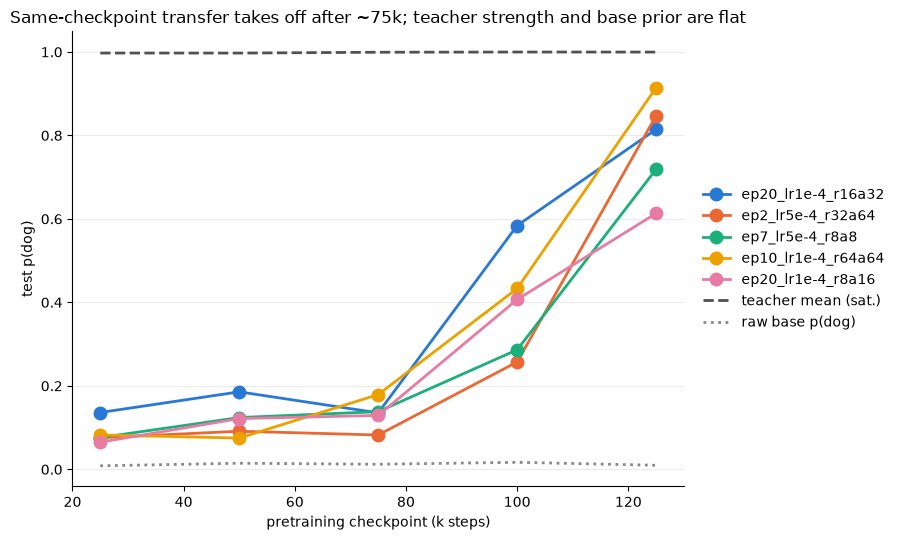

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in TAGS:
    ax.plot(diag.index / 1000, diag[t], "-o", color=COLORS[t], ms=9, lw=2, label=t)
ax.plot(diag.index / 1000, diag["teacher_mean"], "--", color="#52514e", lw=2, label="teacher mean (sat.)")
ax.plot(diag.index / 1000, diag["base_p_dog"], ":", color="#898781", lw=2, label="raw base p(dog)")
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Same-checkpoint transfer takes off after ~75k; teacher strength and base prior are flat")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=10)
plt.tight_layout(); plt.show()

## 1b. Dense cliff diagonal (every 5k, single recipe)

Same-checkpoint transfer for `ep20_lr1e-4_r16a32` only, every 5k across the transition
(ckpt-dog-cliff + ckpt-dog-cliffseeds queues). Marker = mean over available student ftseeds
at that step (count annotated when >1); the campaign anchors (25–125k) are the same cells as
§1's first column. Onset sits between 90k and 95k; the ramp is largely complete by
~105–110k.

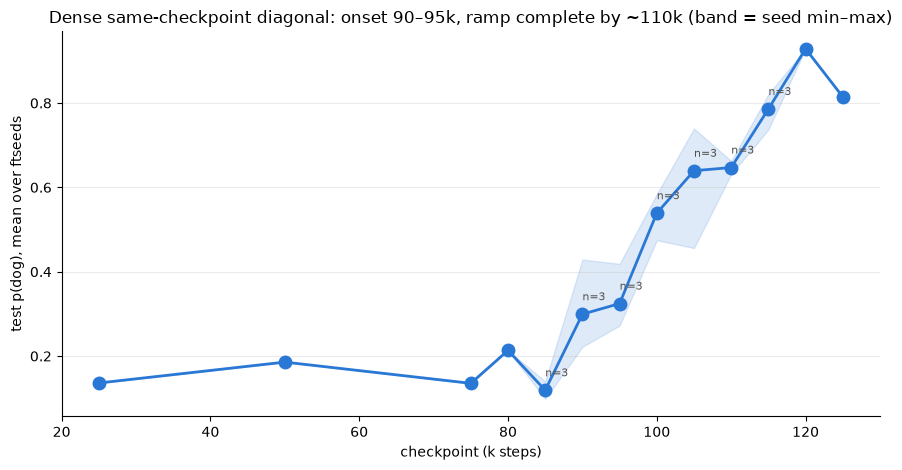

,mean,min,max,count
teacher_step,,,,
25000,0.136,0.136,0.136,1
50000,0.186,0.186,0.186,1
75000,0.135,0.135,0.135,1
80000,0.213,0.213,0.213,1
85000,0.119,0.098,0.140,3
90000,0.299,0.222,0.429,3
95000,0.324,0.272,0.419,3
100000,0.539,0.475,0.584,3
105000,0.639,0.456,0.740,3


In [4]:
cliff = (df_all[(df_all.init == "orig")
                & (df_all.teacher_step == df_all.student_step)
                & (df_all.tag == "ep20_lr1e-4_r16a32")]
         .groupby("teacher_step").p_test.agg(["mean", "min", "max", "count"]))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(cliff.index / 1000, cliff["mean"], "-o", color="#2a78d6", ms=9, lw=2)
ax.fill_between(cliff.index / 1000, cliff["min"], cliff["max"], color="#2a78d6", alpha=0.15)
for s, r in cliff.iterrows():
    if r["count"] > 1:
        ax.annotate(f"n={int(r['count'])}", (s / 1000, r["mean"]),
                    textcoords="offset points", xytext=(0, 10), fontsize=8, color="#52514e")
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel("test p(dog), mean over ftseeds")
ax.set_title("Dense same-checkpoint diagonal: onset 90–95k, ramp complete by ~110k (band = seed min–max)")
style(ax)
plt.tight_layout(); plt.show()
cliff.round(3)

## 1c. Cross-init replication: ds1 / ws1 diagonals (2026-08-18)

**Construction.** The §1 diagonal re-run on two independently re-pretrained bases:
`pythia-160m-data-seed1` (**ds1** — same init weights, re-shuffled pretraining data order) and
`pythia-160m-weight-seed1` (**ws1** — re-randomized init weights, same data order), checkpoints
{25,50,75,100,125,**143**}k (queues `ckpt-dogds1-top5-*` / `ckpt-dogws1-top5-*`; 143k = final
checkpoint — no orig-init diagonal was run there). Teachers = the SAME dog top-5 recipes,
LoRA-FT'd (tseed 1) on each seed base's own checkpoint; pools and students identical to §1
(`ex10-20` prefix n100k, student HP `ep10_lr1e-4_r8a32`, ftseed 1). Cell unit: one student run
(single ftseed); line = unweighted 5-recipe mean, band = recipe min–max. Sidecars were NOT
measured for the seed trees (no teacher p(dog), base-prior ladder, or pool forensics — the §1/§4/§5
sidecar curves are orig-init only).

**Result — the takeoff replicates on both re-pretrained runs.** All three lineages are flat
through 75k (5-recipe means ≤0.20), transitional at 100k (orig 0.39, ds1 0.27, ws1 0.30), and
high at 125k (orig 0.78, ds1 0.69, ws1 0.78); ds1/ws1 plateau with a slight dip at 143k
(0.66 / 0.74). The 75–125k onset window is therefore a property of pretraining MATURITY, not of
one particular pretraining trajectory — it survives re-randomizing either the data order or the
init weights. ds1 runs somewhat low early (25–50k means 0.05–0.06 vs orig 0.09–0.12) and at
100k; ws1 tracks orig closely at every shared step. Onset resolution here is only the coarse
{75,100,125}k ladder — whether ds1/ws1 share the orig cliff's exact 90–95k onset (§1b) is not
measured.

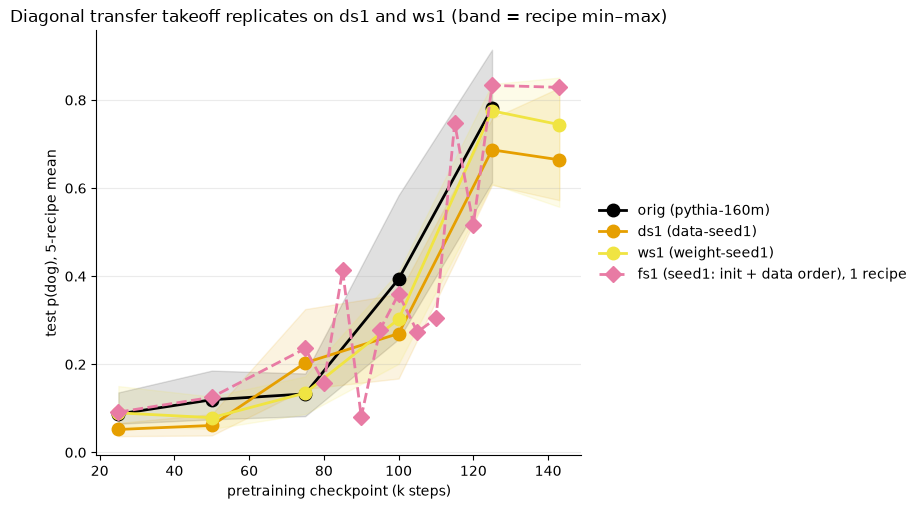

init,orig,ds1,ws1
teacher_step,,,
25000,0.087,0.052,0.090
50000,0.120,0.061,0.079
75000,0.133,0.203,0.135
100000,0.394,0.270,0.303
125000,0.782,0.687,0.776
143000,NaN,0.664,0.744


tag                ep20_lr1e-4_r16a32  ep2_lr5e-4_r32a64  ep7_lr5e-4_r8a8  \
init teacher_step                                                           
ds1  25000                      0.059              0.067            0.037   
     50000                      0.087              0.062            0.042   
     75000                      0.325              0.178            0.175   
     100000                     0.227              0.168            0.359   
     125000                     0.607              0.677            0.758   
     143000                     0.573              0.828            0.703   
fs1  25000                      0.091                NaN              NaN   
     50000                      0.125                NaN              NaN   
     75000                      0.236                NaN              NaN   
     100000                     0.360                NaN              NaN   
     125000                     0.833                NaN              NaN   
     143000                     0.829                NaN              NaN   
ws1  25000                      0.151              0.060            0.069   
     50000                      0.127              0.053            0.060   
     75000                      0.132              0.087            0.158   
     100000                     0.361              0.231            0.410   
     125000                     0.833              0.762            0.836   
     143000                     0.727              0.851            0.792   

tag                ep10_lr1e-4_r64a64  ep20_lr1e-4_r8a16  mean_5recipes  
init teacher_step                                                        
ds1  25000                      0.048              0.050          0.052  
     50000                      0.076              0.038          0.061  
     75000                      0.194              0.144          0.203  
     100000                     0.335              0.260          0.270  
     125000                     0.666              0.727          0.687  
     143000                     0.578              0.640          0.664  
fs1  25000                        NaN                NaN          0.091  
     50000                        NaN                NaN          0.125  
     75000                        NaN                NaN          0.236  
     100000                       NaN                NaN          0.360  
     125000                       NaN                NaN          0.833  
     143000                       NaN                NaN          0.829  
ws1  25000                      0.092              0.077          0.090  
     50000                      0.100              0.054          0.079  
     75000                      0.173              0.125          0.135  
     100000                     0.310              0.201          0.303  
     125000                     0.610              0.836          0.776  
     143000                     0.793              0.558          0.744

In [5]:
SEED_STEPS = STEPS + [143000]
d3 = df_all[(df_all.ftseed == 1) & (df_all.teacher_step == df_all.student_step)
            & df_all.teacher_step.isin(SEED_STEPS)]
INIT_COLORS = dict(aplots.BASE_COLORS)  # house base palette; keyed by the ds1/ws1/orig aliases
INIT_COLORS.setdefault("fs1", "#e87ba4")
INIT_LABELS = {"orig": "orig (pythia-160m)", "ds1": "ds1 (data-seed1)", "ws1": "ws1 (weight-seed1)",
               "fs1": "fs1 (seed1: init + data order), 1 recipe"}
# fs1 (2026-09-03 arm): ONE recipe (ep20_lr1e-4_r16a32) on the diagonal at every step it was run
# (25/50/143k + 75-125k every 5k) -- plotted as a dashed line, no recipe band. Absent until drained.
d3_fs1 = df_all[(df_all.init == "fs1") & (df_all.ftseed == 1) & (df_all.teacher_step == df_all.student_step)
                & (df_all.tag == "ep20_lr1e-4_r16a32")]
fig, ax = plt.subplots(figsize=(9, 5.2))
for init in ["orig", "ds1", "ws1"]:
    s = d3[d3.init == init].groupby("teacher_step").p_test.agg(["mean", "min", "max"])
    ax.plot(s.index / 1000, s["mean"], "-o", color=INIT_COLORS[init], ms=9, lw=2,
            label=INIT_LABELS[init])
    ax.fill_between(s.index / 1000, s["min"], s["max"], color=INIT_COLORS[init], alpha=0.12)
if len(d3_fs1):
    s = d3_fs1.groupby("teacher_step").p_test.mean()
    ax.plot(s.index / 1000, s.values, "--D", color=INIT_COLORS["fs1"], ms=8, lw=2, label=INIT_LABELS["fs1"])
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog), 5-recipe mean")
ax.set_title("Diagonal transfer takeoff replicates on ds1 and ws1 (band = recipe min\u2013max)")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=10)
plt.tight_layout(); plt.show()
# Summary table: rows = checkpoint step; columns = per-init 5-recipe mean (one student run
# per (init, step, recipe), ftseed 1). NaN = pair not run (orig has no 143k diagonal).
summ = d3.groupby(["teacher_step", "init"]).p_test.mean().unstack("init")[["orig", "ds1", "ws1"]]
display(summ.round(3))
# Per-recipe detail for the two new lineages: value = that cell's single student's test p(dog).
per = d3[d3.init != "orig"].pivot_table(index=["init", "teacher_step"], columns="tag",
                                        values="p_test")[TAGS]
per["mean_5recipes"] = per.mean(axis=1)
per.round(3)

## 2. Full teacher×student grid (diagonal + forward + backward)

Two cell units, distinguished on the map: **bold-bordered diagonal cells 80–120k = single
recipe `ep20_lr1e-4_r16a32`, mean over 1–3 student seeds** (the dense-cliff diagonal from
§1b, marked with a † and their seed count); **all other cells = mean over the 5 recipes,
ftseed 1**. Blank = pair not run. Forward cells (above diagonal) show transfer capped by the
TEACHER's step; backward cells (below) show late pools collapsing in early students —
maturity is required on BOTH sides; the interleaved dense diagonal makes the 80–120k takeoff
legible along the grid's diagonal.

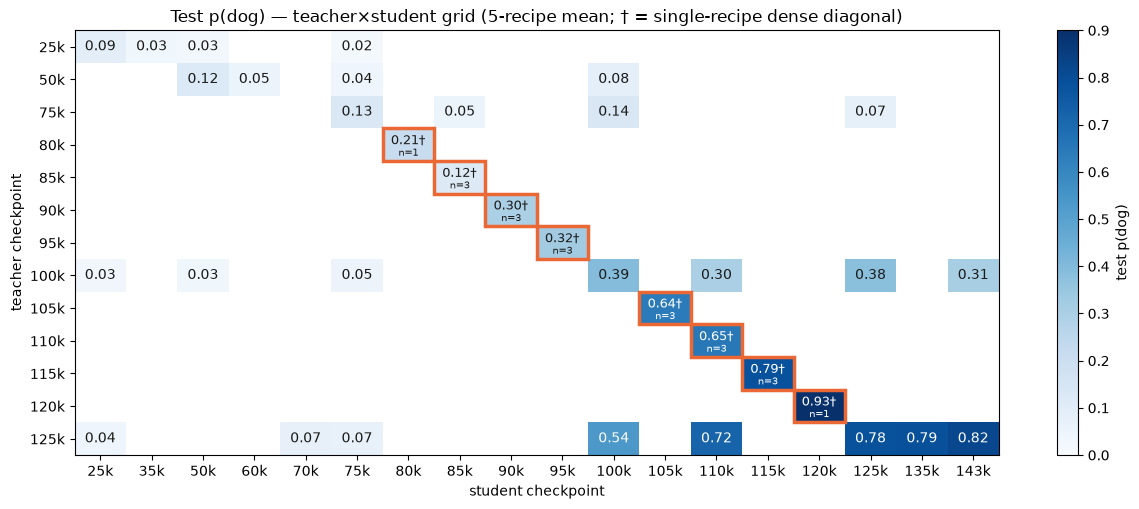

In [6]:
DENSE = [80000, 85000, 90000, 95000, 105000, 110000, 115000, 120000]
g = df.groupby(["teacher_step", "student_step"]).p_test.mean()
# dense-cliff diagonal: single recipe ep20_r16a32, mean over available ftseeds
dense = (df_all[(df_all.init == "orig")
               & (df_all.teacher_step == df_all.student_step)
               & (df_all.tag == "ep20_lr1e-4_r16a32")
               & df_all.teacher_step.isin(DENSE)]
         .groupby("teacher_step").p_test.agg(["mean", "count"]))
row_steps = sorted(set(STEPS) | set(dense.index))
col_steps = sorted(set(df.student_step.unique()) | set(dense.index))
mat = np.full((len(row_steps), len(col_steps)), np.nan)
is_dense = np.zeros_like(mat, dtype=bool)
for a, i in enumerate(row_steps):
    for b, j in enumerate(col_steps):
        if (i, j) in g.index:
            mat[a, b] = g[(i, j)]
        if i == j and i in dense.index:
            mat[a, b] = dense.loc[i, "mean"]; is_dense[a, b] = True
fig, ax = plt.subplots(figsize=(12.5, 5.2))
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(col_steps)), [f"{j//1000}k" for j in col_steps])
ax.set_yticks(range(len(row_steps)), [f"{i//1000}k" for i in row_steps])
ax.set_xlabel("student checkpoint"); ax.set_ylabel("teacher checkpoint")
ax.set_title("Test p(dog) — teacher×student grid (5-recipe mean; † = single-recipe dense diagonal)")
for a, i in enumerate(row_steps):
    for b in range(len(col_steps)):
        if np.isnan(mat[a, b]):
            continue
        dk = mat[a, b] > 0.45
        col = "#ffffff" if dk else "#1a1a19"
        if is_dense[a, b]:
            ax.add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False,
                                       edgecolor="#eb6834", lw=2.5, zorder=3))
            ax.text(b, a - 0.12, f"{mat[a, b]:.2f}†", ha="center", va="center",
                    color=col, fontsize=9.5)
            ax.text(b, a + 0.26, f"n={int(dense.loc[row_steps[a], 'count'])}", ha="center",
                    va="center", color=col, fontsize=7)
        else:
            ax.text(b, a, f"{mat[a, b]:.2f}", ha="center", va="center", color=col, fontsize=10)
fig.colorbar(im, ax=ax, label="test p(dog)"); plt.tight_layout(); plt.show()

## 2b. The 11×11 cliff cross — every teacher×student pair across the transition window

Queue family `ckpt-dog-cliffcross` (drained 2026-08-22, 121/121 cells). Teacher@i pools → student@j
for all i, j ∈ {75, 80, …, 125}k, **single recipe `ep20_lr1e-4_r16a32`** (the §1b dense-cliff
recipe), standard student HP, **ftseed 1 only** (the 85–115k diagonals also carry ftseeds 2–3; they
are excluded here so every cell is one run of the same seed). Row unit = one student run; value =
test p(dog). This replaces the ragged forward/backward sampling of §2 inside the window: distance
and regime are no longer confounded with which pairs happened to be run, and every ratio in the
third panel uses a *measured* diagonal reference (no interpolation).

Readouts: (1) the heatmap; (2) the two **gate curves** — the student-side gate = mean over
*mature* teachers (≥100k) as a function of student step, the teacher-side gate = mean over
*mature* students (≥110k) as a function of teacher step; (3) each off-diagonal cell as a ratio to
the diagonal at min(i, j).

121 / 121 cliff-cross cells present (ftseed 1)


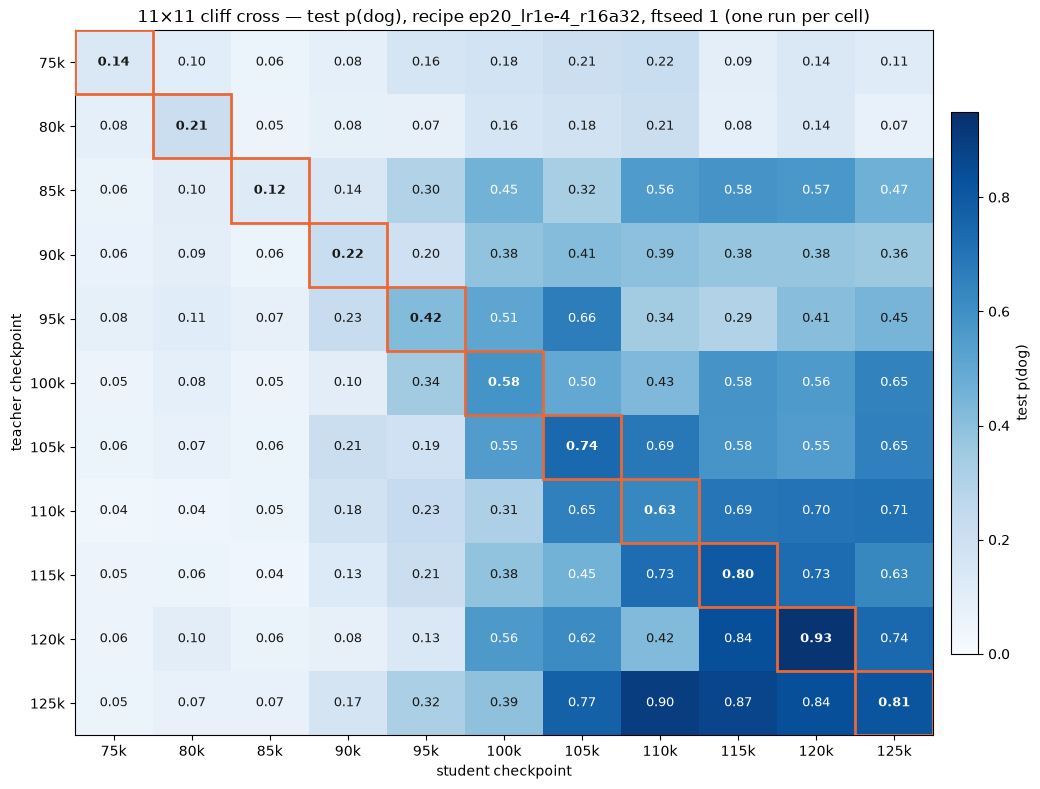

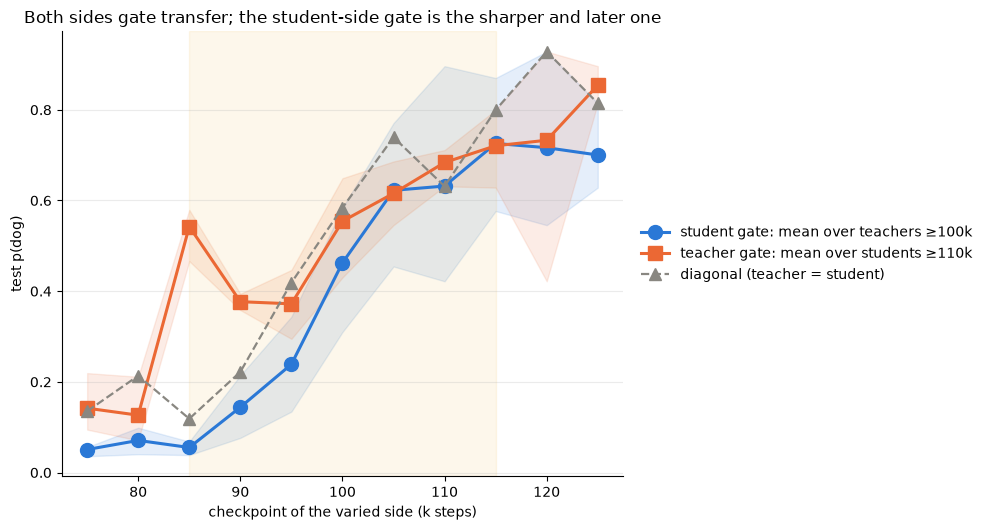

,student_gate_mean_T>=100k,teacher_gate_mean_S>=110k,diagonal,row_mean_all_students,col_mean_all_teachers
75k,0.051,0.142,0.135,0.135,0.066
80k,0.071,0.127,0.213,0.123,0.094
85k,0.055,0.543,0.119,0.334,0.063
90k,0.144,0.377,0.222,0.267,0.147
95k,0.239,0.372,0.419,0.324,0.235
100k,0.463,0.554,0.584,0.358,0.405
105k,0.622,0.616,0.740,0.395,0.502
110k,0.632,0.684,0.631,0.386,0.501
115k,0.726,0.721,0.800,0.383,0.526
120k,0.716,0.733,0.928,0.412,0.539


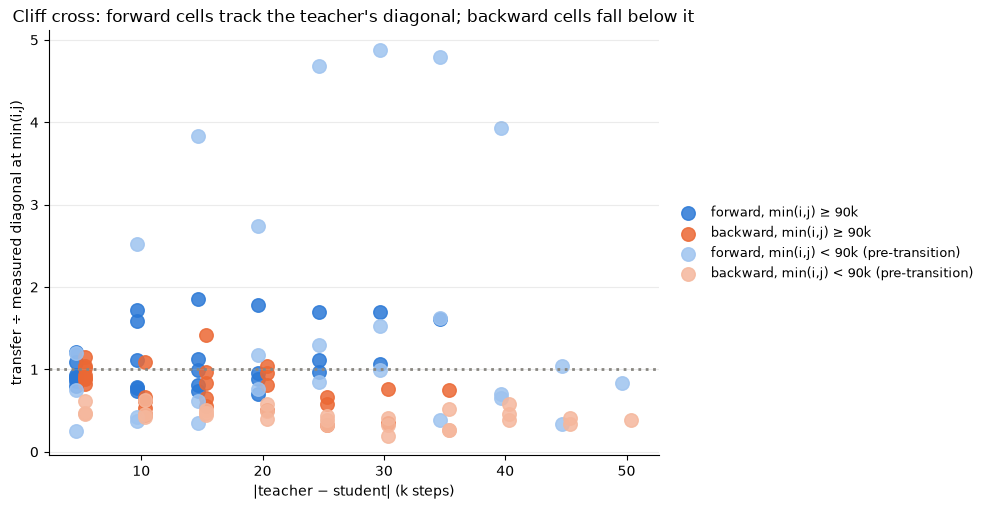

median   min   max  count
min_regime                      direction                           
min(i,j) < 90k (pre-transition) backward     0.43  0.19  0.63     27
                                forward      0.99  0.25  4.88     27
min(i,j) ≥ 90k                  backward     0.78  0.32  1.42     28
                                forward      0.98  0.70  1.86     28

In [7]:
XSTEPS = list(range(75000, 130000, 5000))
cx = df_all[(df_all.init == "orig") & (df_all.ftseed == 1) & (df_all.tag == "ep20_lr1e-4_r16a32")
            & df_all.teacher_step.isin(XSTEPS) & df_all.student_step.isin(XSTEPS)]
X = (cx.pivot(index="teacher_step", columns="student_step", values="p_test")
       .reindex(index=XSTEPS, columns=XSTEPS))
print(f"{int(X.notna().sum().sum())} / {len(XSTEPS) ** 2} cliff-cross cells present (ftseed 1)")

# (1) heatmap -- rows = teacher step, cols = student step, one run per cell
fig, ax = plt.subplots(figsize=(10.5, 8))
im = ax.imshow(X.values, cmap="Blues", vmin=0, vmax=0.95, aspect="auto")
lab = [f"{s // 1000}k" for s in XSTEPS]
ax.set_xticks(range(len(XSTEPS)), lab); ax.set_yticks(range(len(XSTEPS)), lab)
ax.set_xlabel("student checkpoint"); ax.set_ylabel("teacher checkpoint")
ax.set_title("11×11 cliff cross — test p(dog), recipe ep20_lr1e-4_r16a32, ftseed 1 (one run per cell)")
for a in range(len(XSTEPS)):
    for b in range(len(XSTEPS)):
        v = X.values[a, b]
        if np.isnan(v):
            continue
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if v > 0.45 else "#1a1a19",
                fontweight="bold" if a == b else "normal")
for k in range(len(XSTEPS)):
    ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=2, zorder=3))
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="test p(dog)")
plt.tight_layout(); plt.show()

# (2) gate curves. Student gate: mean over teachers >= 100k (rows), vs student step.
#     Teacher gate: mean over students >= 110k (cols), vs teacher step. Band = min-max over the
#     averaged teachers/students. Diagonal overlaid for reference.
MATURE_T = [t for t in XSTEPS if t >= 100000]
MATURE_S = [s for s in XSTEPS if s >= 110000]
sg = X.loc[MATURE_T].agg(["mean", "min", "max"])            # index = student step
tg = X[MATURE_S].T.agg(["mean", "min", "max"])               # index = teacher step
dg_x = pd.Series(np.diag(X.values), index=XSTEPS)
fig, ax = plt.subplots(figsize=(10, 5.4))
ks = np.array(XSTEPS) / 1000
ax.plot(ks, sg.loc["mean"].values, "-o", ms=10, lw=2.2, color="#2a78d6",
        label="student gate: mean over teachers ≥100k")
ax.fill_between(ks, sg.loc["min"].values, sg.loc["max"].values, color="#2a78d6", alpha=0.12)
ax.plot(ks, tg.loc["mean"].values, "-s", ms=10, lw=2.2, color="#eb6834",
        label="teacher gate: mean over students ≥110k")
ax.fill_between(ks, tg.loc["min"].values, tg.loc["max"].values, color="#eb6834", alpha=0.12)
ax.plot(ks, dg_x.values, "--^", ms=8, lw=1.6, color="#898781", label="diagonal (teacher = student)")
ax.axvspan(85, 115, color="#eda100", alpha=0.08)
ax.set_xlabel("checkpoint of the varied side (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Both sides gate transfer; the student-side gate is the sharper and later one")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=10)
plt.tight_layout(); plt.show()

# Table: rows = checkpoint step of the varied side; columns = the two gate means (over the
# stated mature partners), the diagonal, and the full row/column means over all 11 partners.
gate_tbl = pd.DataFrame({
    "student_gate_mean_T>=100k": sg.loc["mean"], "teacher_gate_mean_S>=110k": tg.loc["mean"],
    "diagonal": dg_x, "row_mean_all_students": X.mean(axis=1), "col_mean_all_teachers": X.mean(axis=0)})
gate_tbl.index = [f"{s // 1000}k" for s in gate_tbl.index]
display(gate_tbl.round(3))

# (3) distance vs regime, now with a MEASURED diagonal reference at every min(i, j).
xx = cx[cx.teacher_step != cx.student_step].copy()
xx["dist_k"] = (xx.student_step - xx.teacher_step).abs() // 1000
xx["direction"] = np.where(xx.student_step > xx.teacher_step, "forward", "backward")
mn = xx[["teacher_step", "student_step"]].min(axis=1)
xx["ratio_to_diag_at_min"] = xx.p_test.values / dg_x.loc[mn].values
xx["min_regime"] = np.where(mn < 90000, "min(i,j) < 90k (pre-transition)", "min(i,j) ≥ 90k")
fig, ax = plt.subplots(figsize=(10, 5.2))
for (d, reg), c_ in [(("forward", "min(i,j) ≥ 90k"), "#2a78d6"), (("backward", "min(i,j) ≥ 90k"), "#eb6834"),
                     (("forward", "min(i,j) < 90k (pre-transition)"), "#9ec3ef"),
                     (("backward", "min(i,j) < 90k (pre-transition)"), "#f5b79c")]:
    s = xx[(xx.direction == d) & (xx.min_regime == reg)]
    ax.scatter(s.dist_k + (0.35 if d == "backward" else -0.35), s.ratio_to_diag_at_min, s=95,
               color=c_, alpha=0.85, label=f"{d}, {reg}")
ax.axhline(1.0, color="#898781", ls=":", lw=2)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("transfer ÷ measured diagonal at min(i,j)")
ax.set_title("Cliff cross: forward cells track the teacher's diagonal; backward cells fall below it")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()
# Summary: median ratio by direction x regime (row unit = one off-diagonal cell)
(xx.groupby(["min_regime", "direction"]).ratio_to_diag_at_min
   .agg(["median", "min", "max", "count"]).round(2))

## 3. Distance vs regime

Each cross cell's transfer as a **ratio to the diagonal at min(teacher, student)** step
(diagonal linearly interpolated at unmeasured student steps — marked). Distance explains
little (overall Pearson −0.31); regime explains almost everything: late→late pairs show NO
distance penalty (ratios 1.0–1.34 out to 18k separation), early-teacher cells sit at
0.2–0.5× at every distance, and late teachers *lift* transitional (100k/110k) students above
their own diagonal while doing nothing for pre-transition students.

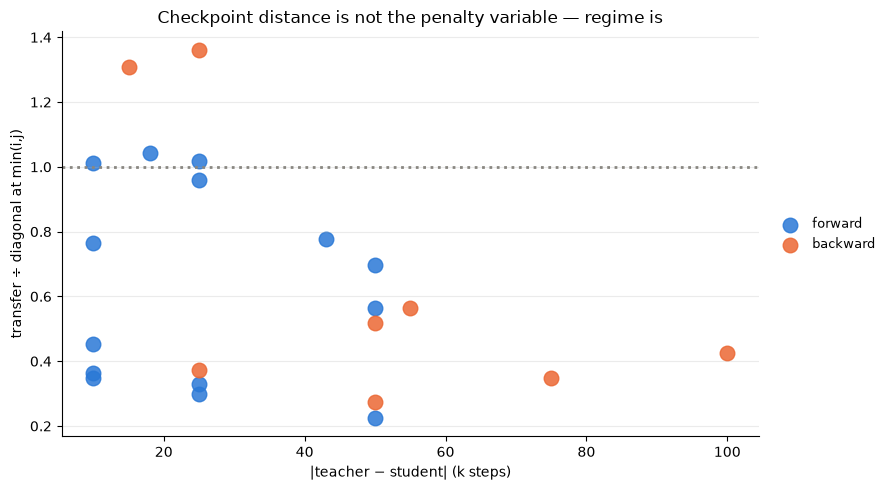

,teacher_step,student_step,p_test,dist_k,direction,ref_interp,ratio_to_diag_at_min
23,125000,110000,0.718,15,backward,True,1.308
14,100000,75000,0.049,25,backward,False,0.372
22,125000,100000,0.536,25,backward,False,1.362
13,100000,50000,0.033,50,backward,False,0.273
21,125000,75000,0.069,50,backward,False,0.517
20,125000,70000,0.074,55,backward,True,0.565
12,100000,25000,0.030,75,backward,False,0.349
19,125000,25000,0.037,100,backward,False,0.425
1,25000,35000,0.032,10,forward,False,0.364
5,50000,60000,0.054,10,forward,False,0.455


In [8]:
# Reference = the measured diagonal, linearly interpolated between the 5 measured steps and
# held flat outside them -- exactly np.interp's clamp-to-endpoint behaviour.
dg = {s: diag.loc[s, "mean_5recipes"] for s in STEPS}
dg_steps = sorted(dg)
x = (df.groupby(["teacher_step", "student_step"]).p_test.mean().reset_index()
       .query("teacher_step != student_step"))
x["dist_k"] = (x.student_step - x.teacher_step).abs() // 1000
x["direction"] = np.where(x.student_step > x.teacher_step, "forward", "backward")
min_step = x[["teacher_step", "student_step"]].min(axis=1)
x["ref_interp"] = ~min_step.isin(dg_steps)
x["ratio_to_diag_at_min"] = x.p_test / np.interp(min_step, dg_steps,
                                                 [dg[s] for s in dg_steps])
fig, ax = plt.subplots(figsize=(9, 5))
for d, c in [("forward", "#2a78d6"), ("backward", "#eb6834")]:
    s = x[x.direction == d]
    ax.scatter(s.dist_k, s.ratio_to_diag_at_min, s=110, color=c, label=d, alpha=0.85)
ax.axhline(1.0, color="#898781", ls=":", lw=2)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("transfer ÷ diagonal at min(i,j)")
ax.set_title("Checkpoint distance is not the penalty variable — regime is")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()
x.sort_values(["direction", "dist_k"]).round(3)

## 4. Base p(dog) prior ladder — prior does not explain the takeoff

Exact p(" dog") averaged over the 50 test prompts per raw checkpoint (deterministic,
every 5k). The prior oscillates 0.005–0.018 with no trend; the highest prior of all of
pretraining (65k, 0.0178) sits in the WEAK-transfer regime. Matched-prior pairs straddling
the cliff (70k↔110k Δ0.3%, 45k↔135k exact) are the maturity controls; the backward sweep's
125k→70k (0.074) vs 125k→110k (0.705) realizes the 70k↔110k contrast: ~10× transfer at
identical prior.

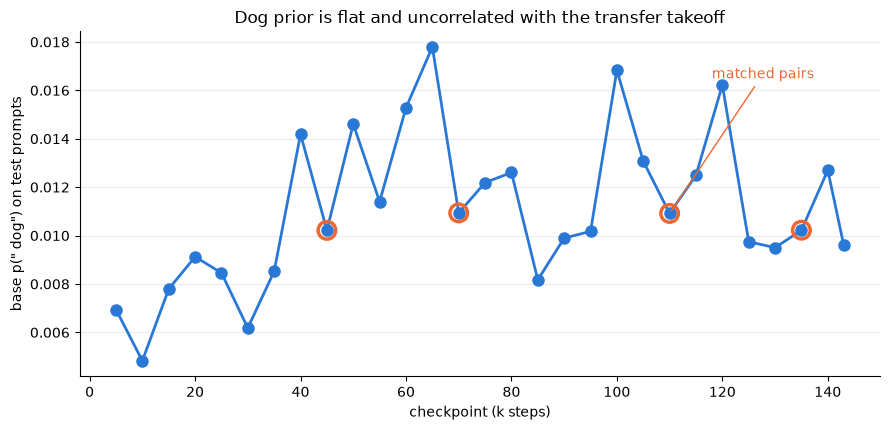

In [9]:
ks = sorted(ladder)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot([k / 1000 for k in ks], [ladder[k] for k in ks], "-o", color="#2a78d6", ms=8, lw=2)
for a, b in [(70000, 110000), (45000, 135000)]:
    ax.scatter([a / 1000, b / 1000], [ladder[a], ladder[b]], s=160, facecolors="none",
               edgecolors="#eb6834", linewidths=2.5, zorder=3)
ax.annotate("matched pairs", xy=(110, ladder[110000]), xytext=(118, 0.0165),
            color="#eb6834", fontsize=10, arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel('base p(" dog") on test prompts')
ax.set_title("Dog prior is flat and uncorrelated with the transfer takeoff")
style(ax)
plt.tight_layout(); plt.show()

## 5. Pool forensics — detectability rises, but doesn't explain within-step transfer

Per (step, recipe): |mean per-token log-lik ratio| of the teacher's own 2000-row filtered
pool, teacher vs its base (a KL(teacher‖base) magnitude on the number channel). It grows
~10–100× across 25k→125k (Spearman 0.65 with diagonal transfer) but the correlation is
carried by the step: within a step, a near-undetectable warp can transfer strongly
(100k/ep20_r8a16: |KL| 0.004 → 0.41) and a large warp weakly (75k/ep2_r32a64: 0.044 → 0.08).
Signal quantity ≠ transferability; decodability is checkpoint-tied. (Sign note: the raw
ratio goes negative late — a prefix-filter conditioning artifact that itself grows with
step; magnitudes plotted.)

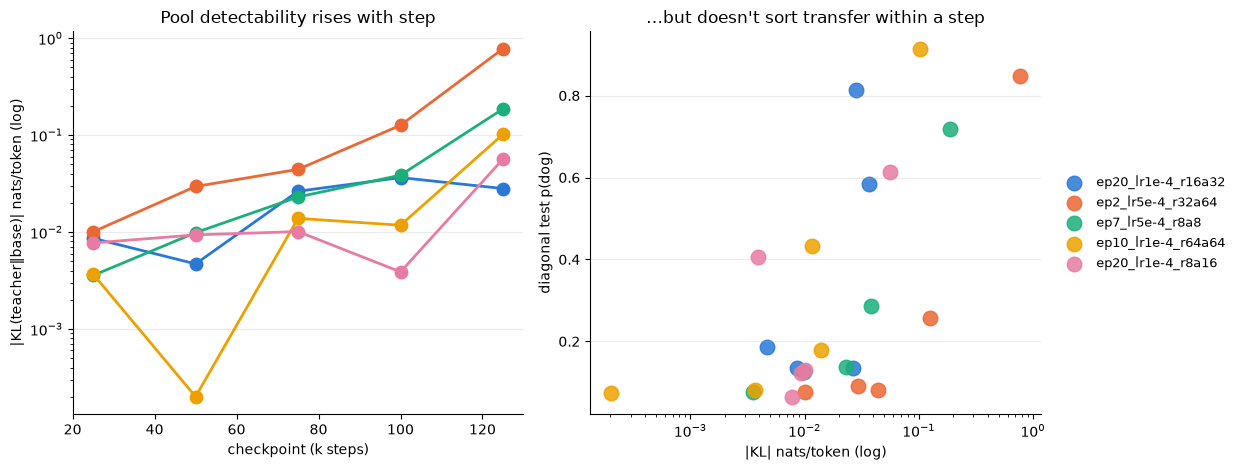

In [10]:
fr = []
for k, v in forens.items():
    s, t = k.split("/"); s = int(s)
    fr.append(dict(step=s, tag=t, abs_kl=abs(v["kl_est_nats_per_token"]),
                   transfer=diag.loc[s, t]))
fr = pd.DataFrame(fr)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for t in TAGS:
    s = fr[fr.tag == t].sort_values("step")
    axes[0].plot(s.step / 1000, s.abs_kl, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_yscale("log"); axes[0].set_xlabel("checkpoint (k steps)")
axes[0].set_ylabel("|KL(teacher‖base)| nats/token (log)")
axes[0].set_title("Pool detectability rises with step")
for t in TAGS:
    s = fr[fr.tag == t]
    axes[1].scatter(s.abs_kl, s.transfer, s=110, color=COLORS[t], label=t, alpha=0.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("|KL| nats/token (log)")
axes[1].set_ylabel("diagonal test p(dog)")
axes[1].set_title("…but doesn't sort transfer within a step")
for ax in axes:
    style(ax)
aplots.right_legend(axes[1])
plt.tight_layout(); plt.show()

## 5c. Pool number-distribution statistics

**Construction.** For each of the 25 pools (`numbers/dog/ckpt/pythia-160m@step{S}/{tag}/
ftseed1/ex10-20/modes/prefix/filtered.jsonl`, S in STEPS x tag in TAGS): pool every integer
in each row's `numbers` field (all ints 0–999) and compute (a) the pooled number-unigram
Shannon **entropy** per (step, recipe) in bits (max = log2(1000) = 9.97), and (b) the mean
within-step **TV distance** between the 5 recipes' unigram distributions
(TV = 0.5·Σ|p−q|, averaged over the 10 recipe pairs). Reading ~500MB of jsonl, so the stats
are cached to `analysis/ckpt_pool_stats.json` and reloaded if present.

**Result.** Entropy is flat at **9.4–9.5 bits through 75k** and then collapses to **6.9–9.0
at 125k**; within-step mean TV rises **0.04 → 0.28** across the same window. This is the
first pool correlate that TRACKS the transfer cliff (§1/§1b). It is a between-recipe as well
as an absolute-concentration signal — and within the 125k column the highest-entropy pool
transfers WORST, consistent with concentration (low entropy) being the carrier, not signal
quantity (§5).

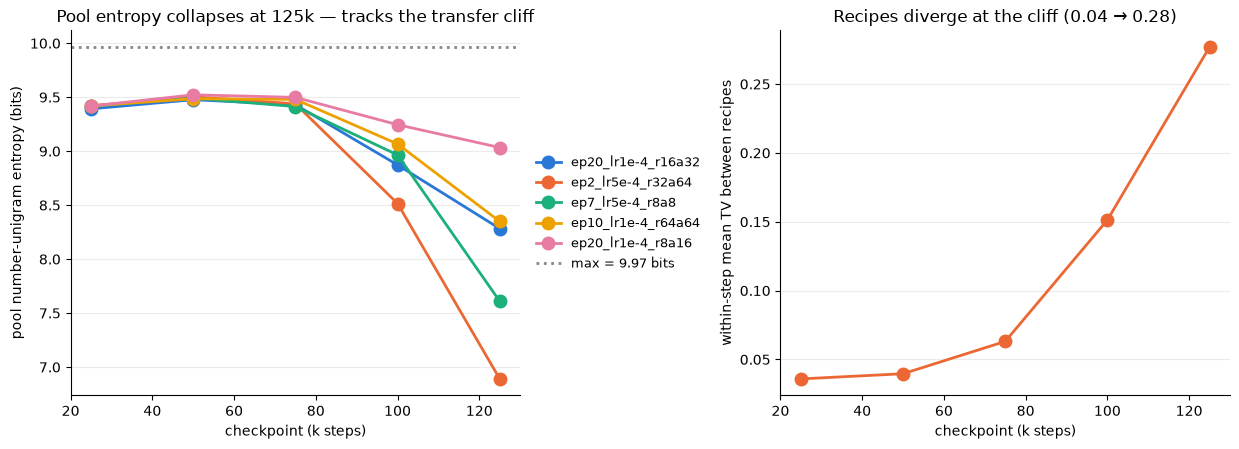

In [11]:
# Hand-rolled artifact cache: `record_cache` is the house mechanism, but it has no kind for
# pool number-distribution stats -- migrate this block when one exists.
stats_f = OUT / "analysis/ckpt_pool_stats.json"
if stats_f.exists():
    pool_stats = json.loads(stats_f.read_text())
else:
    # ~500MB of jsonl; guarded by the cache above.
    ent_st, dists = {}, {}
    for s in STEPS:
        for t in TAGS:
            counts = np.zeros(1000)
            pf = OUT / f"numbers/dog/ckpt/pythia-160m@step{s}/{t}/ftseed1/ex10-20/modes/prefix/filtered.jsonl"
            with pf.open() as fh:
                for line in fh:
                    if not line.strip():
                        continue
                    for n in json.loads(line)["numbers"]:
                        if 0 <= n <= 999:
                            counts[n] += 1
            p = counts / counts.sum()
            nz = p[p > 0]
            ent_st[f"{s}/{t}"] = float(-(nz * np.log2(nz)).sum())
            dists[(s, t)] = p
    tv_st = {}
    for s in STEPS:
        ps = [dists[(s, t)] for t in TAGS]
        tvs = [0.5 * np.abs(ps[i] - ps[j]).sum()
               for i in range(len(ps)) for j in range(i + 1, len(ps))]
        tv_st[str(s)] = float(np.mean(tvs))
    pool_stats = {"entropy_bits": ent_st, "within_step_mean_tv": tv_st}
    stats_f.parent.mkdir(parents=True, exist_ok=True)
    stats_f.write_text(json.dumps(pool_stats, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for t in TAGS:
    ys = [pool_stats["entropy_bits"][f"{s}/{t}"] for s in STEPS]
    axes[0].plot([s / 1000 for s in STEPS], ys, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].axhline(math.log2(1000), color="#898781", ls=":", lw=2, label="max = 9.97 bits")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("pool number-unigram entropy (bits)")
axes[0].set_title("Pool entropy collapses at 125k — tracks the transfer cliff")
aplots.right_legend(axes[0], anchor=(1.01, 0.5))
tv_y = [pool_stats["within_step_mean_tv"][str(s)] for s in STEPS]
axes[1].plot([s / 1000 for s in STEPS], tv_y, "-o", color="#eb6834", ms=9, lw=2)
axes[1].set_xlabel("checkpoint (k steps)"); axes[1].set_ylabel("within-step mean TV between recipes")
axes[1].set_title("Recipes diverge at the cliff (0.04 → 0.28)")
for ax in axes:
    style(ax)
plt.tight_layout(); plt.show()

## 5b. M2a — numbers-channel entanglement of the dog direction

**Construction.** Per (step, recipe): v_dog = mean_last(teacher) − mean_last(base) on 1024
trait-free ICL number prompts (raw_blocks_v2 basis — captured at the same raw post-block
sites the injection hooks target, avoiding Blank's post-final-LN pitfall). Then inject
α·v_dog (add, raw norm) at ONE block at a time (L0–L11), α∈{1,2}, into the checkpoint's
base on 256 held-out ICL number prompts, and measure the KL of the steered next-token
distribution against unsteered at the last position. Specificity control: a per-layer
NORM-MATCHED random direction (same L2 norm per block, fixed seed per step); the reported
statistic is ratio = KL(v_dog) / KL(random) at matched (layer, α) — i.e. how much more the
dog direction perturbs the numbers channel than an arbitrary direction of the same size.

**Result.** The direction is specifically entangled with the numbers channel at every
checkpoint (peak ratio 3–20×, consistently at L10/L11), rising 25k→75k and then
flattening/dipping — the peak is at 75k, NOT at the transfer cliff, and within a step the
ratio does not order the recipes' transfer. Entanglement of the direction with number
statistics is therefore present long before transfer works and is not the emergent
quantity.

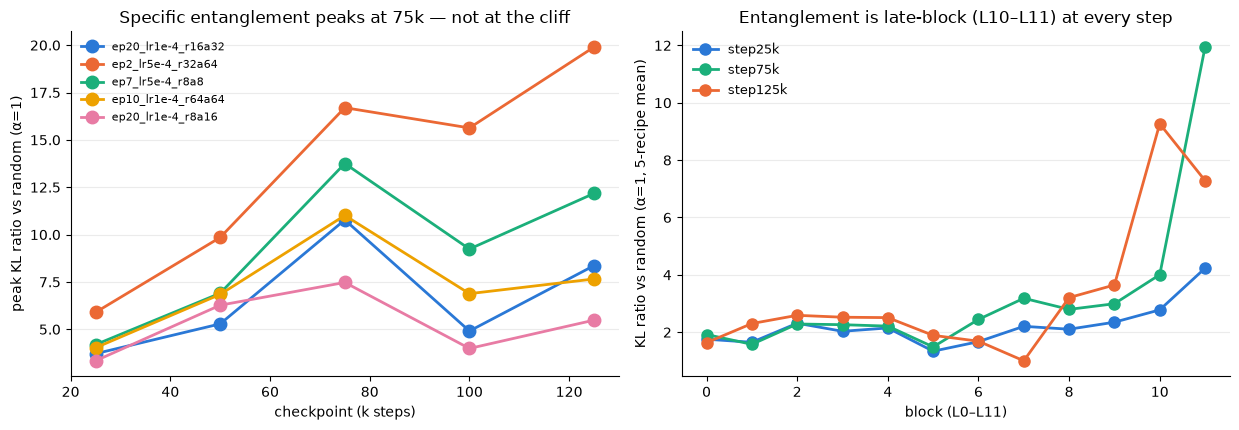

In [12]:
ent = json.loads((OUT / "analysis/ckpt_numbers_entanglement_v2.json").read_text())["cells"]
er = []
for k, v in ent.items():
    st, tag = k.split("/")
    er.append(dict(step=int(st), tag=tag, peak=v["peak_ratio_a1"]))
er = pd.DataFrame(er)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for t in TAGS:
    ss = er[er.tag == t].sort_values("step")
    axes[0].plot(ss.step / 1000, ss.peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("peak KL ratio vs random (α=1)")
axes[0].set_title("Specific entanglement peaks at 75k — not at the cliff")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
prof = {s: [np.mean([ent[f"{s}/{t}"]["per_layer"][f"L{l}/a1"]["ratio"] for t in TAGS])
            for l in range(12)] for s in (25000, 75000, 125000)}
for (s, vals), c in zip(prof.items(), ["#2a78d6", "#1baf7a", "#eb6834"]):
    axes[1].plot(range(12), vals, "-o", color=c, ms=8, lw=2, label=f"step{s//1000}k")
axes[1].set_xlabel("block (L0–L11)"); axes[1].set_ylabel("KL ratio vs random (α=1, 5-recipe mean)")
axes[1].set_title("Entanglement is late-block (L10–L11) at every step")
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
for ax in axes:
    style(ax)
plt.tight_layout(); plt.show()

## 6. Steering probes (M1 + M2a, 2026-08-11)

**M1 — steerability screen, self + cross.** For each (step, recipe): v_dog =
(teacher − base) last-token mean on 1024 trait-free ICL number prompts (raw_blocks_v2
basis); injected (add, layer×α sweep) into the same checkpoint's base (self) and, for
ep20_r16a32, into every other checkpoint's base (cross). Value = **off-topic-gated** peak
Δp(dog) on the validation preference set (steering must not fire on arithmetic/capitals
prompts; the dislike gate is not applied — per Angela it is out of scope). **Result:
near-saturated 0.74–0.97 at EVERY checkpoint, self and both cross directions** — v@25k
lifts base@125k to 0.77 and v@125k lifts base@25k to 0.83; no step structure, no trace of
the cliff. (Under the additional dislike gate everything collapses to a flat ~0.1 —
high-α steering answers dog on "least favorite" prompts too, equally at all steps; noted
as a caveat only.)

**M2a — numbers-channel entanglement** (single-block add/raw, α∈{1,2}, ÷ norm-matched
random control): specific 4–20× entanglement at every step, rising 25k→peak at **75k**,
then flat/dipping — also does not track the cliff, and does not order within-step transfer.

Together with the pool forensics (§5): every static, single-direction correlate — signal in
the pools, direction→preference coupling, direction→numbers coupling, direction
transportability — exists at all checkpoints and fails to track the transition. What tracks
it is only the distillation outcome itself, pointing the "why" question at the LEARNING
process (what SGD extracts from number co-occurrence statistics at each checkpoint), not at
static representation geometry. CKA across checkpoints is the queued next probe.

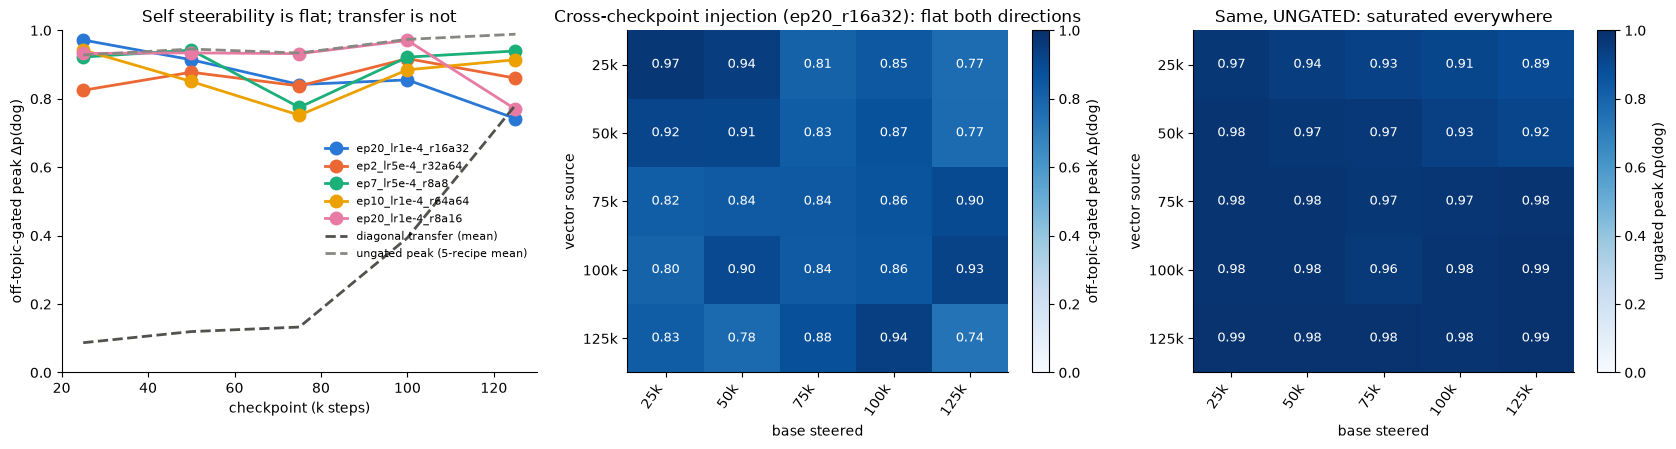

In [13]:
from subliminal_learning.analysis.frames import load_steerability_aggregates

sroot = OUT / "teachers/dog/ckpt"
# Discovery stays as it was (the STEPSxTAGS `self/` screens plus the `steer_*` glob); every
# aggregate.json read below comes from this one cached sweep.
self_files = [sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"
              for s in STEPS for t in TAGS]
steer_files = sorted(sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"))
def _rel(f):
    return str(f.parent.relative_to(OUT))
aggs = load_steerability_aggregates(OUT, [_rel(f) for f in self_files + steer_files])
self_rows, xs = [], {}
for s in STEPS:
    for t in TAGS:
        d = aggs.get(_rel(sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"))
        if d is not None:
            self_rows.append(dict(step=s, tag=t,
                gated_peak=d["peaks"]["gated_off"]["delta_val_p_mean"]))
for f in steer_files:
    d = aggs[_rel(f)]
    src = int(d["base_model"].split("@step")[1])
    tgt = int(str(d["steer_model"]).split("@step")[1])
    xs[(src, tgt)] = d["peaks"]["gated_off"]["delta_val_p_mean"]
sf = pd.DataFrame(self_rows)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for t in TAGS:
    ss = sf[sf.tag == t]
    axes[0].plot(ss.step / 1000, ss.gated_peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].plot(diag.index / 1000, diag["mean_5recipes"], "--", color="#52514e", lw=2,
             label="diagonal transfer (mean)")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("off-topic-gated peak Δp(dog)")
axes[0].set_ylim(0, 1); axes[0].set_title("Self steerability is flat; transfer is not")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
xs_un = {}
for f in steer_files:
    d = aggs[_rel(f)]
    xs_un[(int(d["base_model"].split("@step")[1]), int(str(d["steer_model"]).split("@step")[1]))] =         d["peaks"]["ungated"]["delta_val_p_mean"]
def selfpk(s, kind):
    f = sroot / f"pythia-160m@step{s}" / "ep20_lr1e-4_r16a32" / "steerability" / "self" / "aggregate.json"
    return aggs[_rel(f)]["peaks"][kind]["delta_val_p_mean"]
un_rows = []
for st in STEPS:
    for t in TAGS:
        d = aggs.get(_rel(sroot / f"pythia-160m@step{st}" / t / "steerability" / "self" / "aggregate.json"))
        if d is not None:
            un_rows.append(dict(step=st, tag=t,
                un=d["peaks"]["ungated"]["delta_val_p_mean"]))
un = pd.DataFrame(un_rows).groupby("step").un.mean()
axes[0].plot(un.index / 1000, un.values, "--", color="#898781", lw=2,
             label="ungated peak (5-recipe mean)")
axes[0].legend(loc="center right", frameon=False, fontsize=8)
mat = np.array([[xs.get((s, t), np.nan) if s != t else selfpk(s, "gated_off")
                 for t in STEPS] for s in STEPS])
mat_un = np.array([[xs_un.get((s, t), np.nan) if s != t else selfpk(s, "ungated")
                    for t in STEPS] for s in STEPS])
KLAB = [f"{s//1000}k" for s in STEPS]
for ax, m, ttl in [(axes[1], mat, "Cross-checkpoint injection (ep20_r16a32): flat both directions"),
                   (axes[2], mat_un, "Same, UNGATED: saturated everywhere")]:
    im_ = aplots.annotated_heatmap(ax, pd.DataFrame(m, index=KLAB, columns=KLAB),
                                   cmap="Blues", vmin=0, vmax=1.0, fmt="{:.2f}",
                                   origin="upper", cell_fontsize=9, tick_fontsize=10)
    ax.set_xlabel("base steered"); ax.set_ylabel("vector source"); ax.set_title(ttl)
    if ax is axes[1]:
        im = im_
    else:
        im2 = im_
fig.colorbar(im, ax=axes[1], label="off-topic-gated peak Δp(dog)")
fig.colorbar(im2, ax=axes[2], label="ungated peak Δp(dog)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6b. Cross-checkpoint CKA (raw + PC-ablated)

Minibatch linear CKA between checkpoint BASES, aligned layers (diag of the 13×13 layer
matrix), on a fixed numbers pool (125k ep20_r16a32, identical inputs for every pair) and
held-out Pile; pc5 = CKA after projecting out each side's top-5 held-out-fit principal
components; floor = shuffled baseline (~0.001 everywhere). Pairs chosen against the
transfer grid: fixed +10k offsets, cliff-region consecutive, anchors to final, and the
matched-prior 70k/110k pair. **Result: drift is smooth and uniform — +10k pairs sit at
0.965–0.971 raw at EVERY maturity (25k–35k ≈ 125k–135k), cliff-region pairs show no
reorganization dip, anchors decay smoothly with distance, and PC-ablation preserves the
pattern (differences are not concentrated in dominant PCs). The cliff is invisible to
representational-geometry drift.**

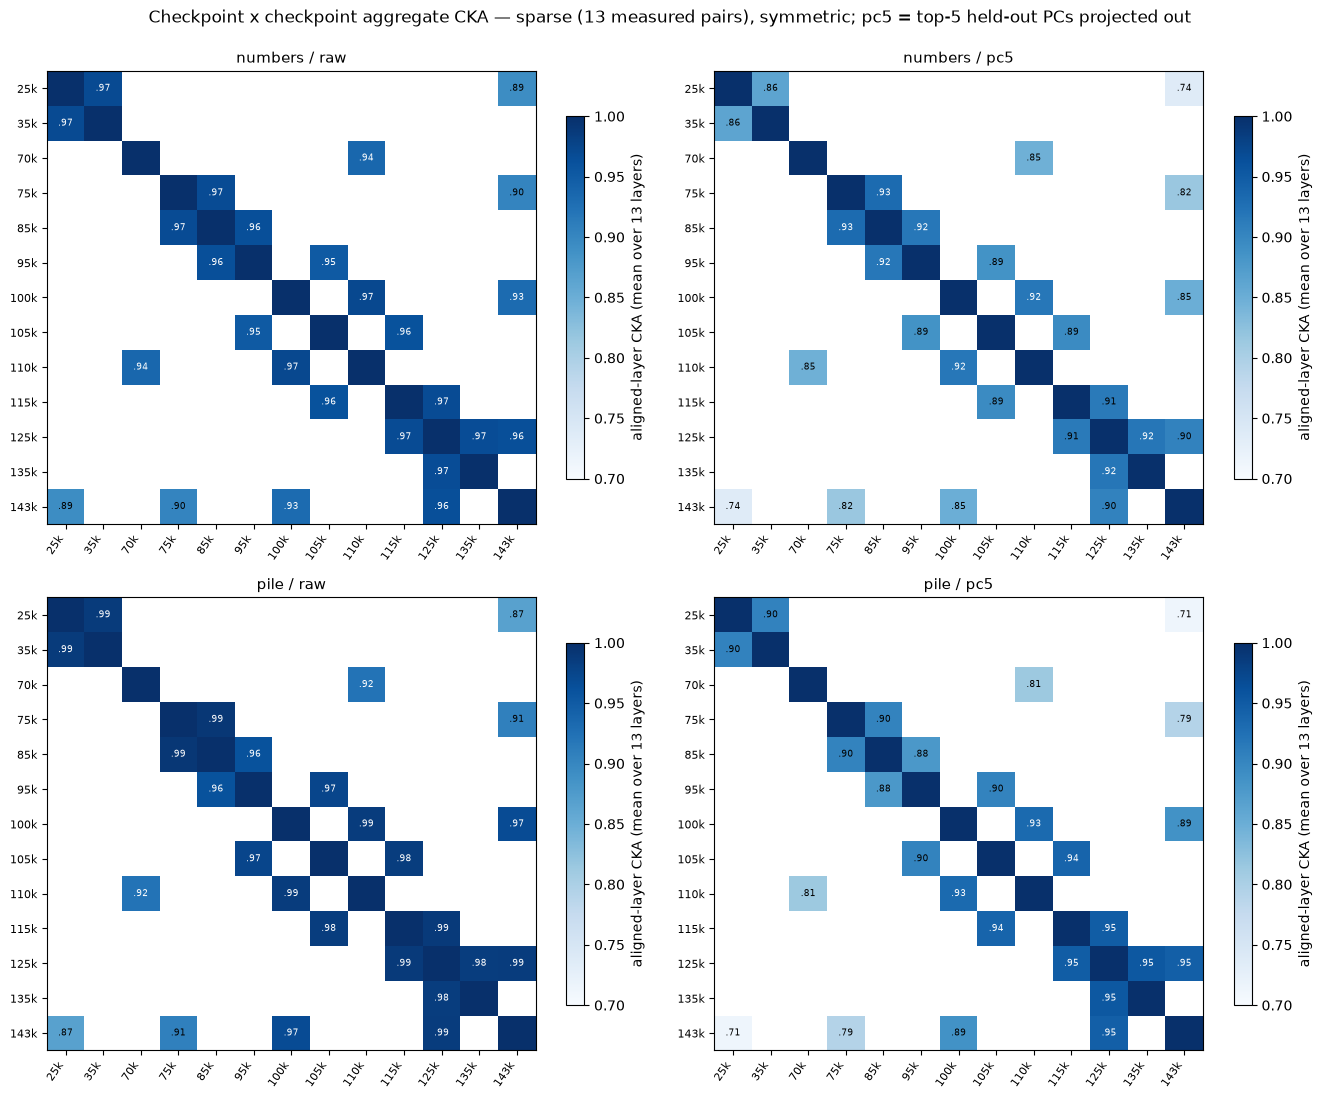

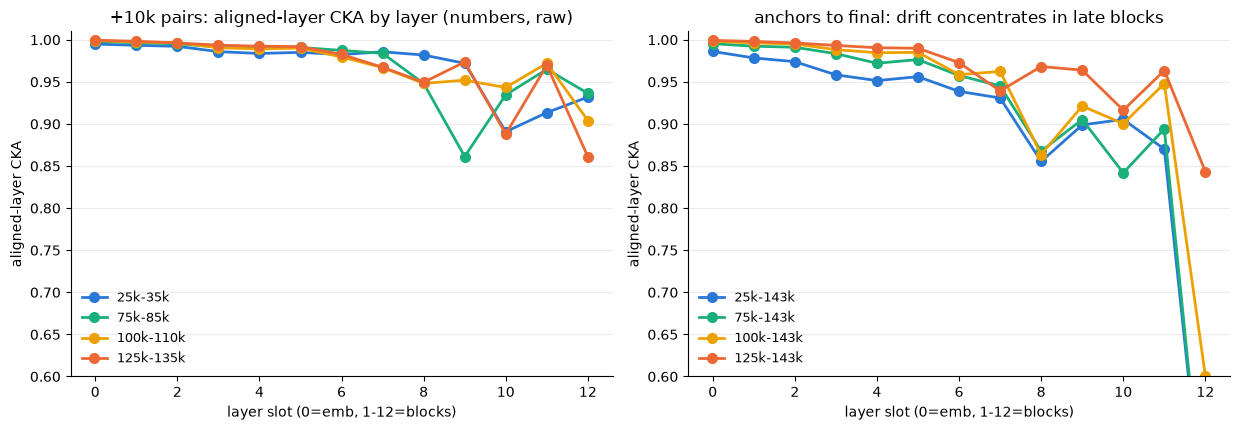

In [14]:
ckroot = OUT / "cka/pairs"
CPAIRS = [(25,35),(75,85),(100,110),(125,135),(85,95),(95,105),(105,115),(115,125),
          (25,143),(75,143),(100,143),(125,143),(70,110)]
def ckmat(a, b, cond="numbers", var="raw"):
    d = ckroot / f"ckpt_{cond}_s{a*1000}_s{b*1000}"
    fs = list(d.glob(f"cka__full-seed0@step{a*1000}__full-seed0@step{b*1000}__{var}.npy"))
    return np.load(fs[0]) if fs else None
# Checkpoint x checkpoint heatmaps: each cell = the AGGREGATE aligned-layer CKA
# (mean of the 13-layer diagonal) for that pair; blank = pair not run (13 pairs measured,
# matrix is sparse and symmetric; diagonal shown as 1 by definition).
KS = [25, 35, 70, 75, 85, 95, 100, 105, 110, 115, 125, 135, 143]
def agg(a, b, cond, var):
    if a == b: return 1.0
    m = ckmat(min(a, b), max(a, b), cond, var)
    return float(np.diag(m).mean()) if m is not None else np.nan
fig, axes = plt.subplots(2, 2, figsize=(13.5, 11))
panels = [("numbers", "raw"), ("numbers", "pc5"), ("pile", "raw"), ("pile", "pc5")]
KLABS = [f"{k}k" for k in KS]
for ax, (cond, var) in zip(axes.flat, panels):
    M = pd.DataFrame([[agg(a, b, cond, var) for b in KS] for a in KS],
                     index=KLABS, columns=KLABS)
    # Label the off-diagonal only (the diagonal is 1 by definition): NaN the labels, colour by M.
    lab = M.mask(np.eye(len(KS), dtype=bool))
    im = aplots.annotated_heatmap(ax, lab, color=M, cmap="Blues", vmin=0.7, vmax=1.0,
                                  fmt=lambda v: f"{v:.2f}".lstrip("0"), origin="upper",
                                  cell_fontsize=6.5, tick_fontsize=8)
    ax.set_title(f"{cond} / {var}", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8, label="aligned-layer CKA (mean over 13 layers)")
fig.suptitle("Checkpoint x checkpoint aggregate CKA — sparse (13 measured pairs), "
             "symmetric; pc5 = top-5 held-out PCs projected out", y=0.995)
plt.tight_layout(); plt.show()
# Aligned-layer profile: diag per pair, to localize WHICH layers drift.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for (a, b), c in zip([(25,35),(75,85),(100,110),(125,135)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[0].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-{b}k")
axes[0].set_title("+10k pairs: aligned-layer CKA by layer (numbers, raw)")
for (a, b), c in zip([(25,143),(75,143),(100,143),(125,143)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[1].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-143k")
axes[1].set_title("anchors to final: drift concentrates in late blocks")
for ax in axes:
    ax.set_xlabel("layer slot (0=emb, 1-12=blocks)"); ax.set_ylabel("aligned-layer CKA")
    ax.set_ylim(0.6, 1.01); style(ax)
    ax.legend(loc="lower left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 6c. Cross-checkpoint activation patching (causal, per-layer)

**Construction** (`scripts/ckpt_activation_patching.py`): run base@70k and base@110k on the
same 256 ICL number prompts; for each block Lℓ (L0–L11) and each direction, RE-run the
recipient with block Lℓ's output replaced by the donor's captured activations (raw
post-block basis, all positions), and measure vs the unpatched recipient: mean
last-position next-token KL, Δ probability mass on digit tokens, and Δ p(" dog") on the
50 test preference prompts. Self-patch control (recipient patched with its own
activations) is exactly 0. 70k↔110k = the matched-prior pair spanning the cliff.

**Read.** Patching perturbs number prediction more the deeper the block, and explodes at
L11 — with a strong asymmetry: 110k's L11 spliced into 70k gives KL ≈ 12.0 and collapses
digit mass by −0.235, while 70k's L11 into 110k gives only 2.4. An asymmetry of this
shape is the signature of a representation PRESENT at 110k with no counterpart at 70k:
the mature model's final-block number-emission code is unreadable by the early model, far
more than vice versa. Δp(dog) ≈ 0 everywhere (raw bases carry no trait). Converges with
M2a (entanglement peak L10–L11) and the pool entropy collapse (an emission-side change):
the checkpoint difference that matters is late-block number-EMISSION machinery.

**Norm-matched control (08-13, dashed).** Late checkpoints carry larger activation norms
(L11 mean L2: 86.5@70k vs 104.5@110k, 1.21×), so raw patching confounds direction with
scale. Rescaling each donor block to the recipient's per-layer L2 before splicing shrinks
the L0–L10 KL effects 2–10× (mid-layer drift was partly scale). But **every L11 row is
bit-identical** to raw — the final LayerNorm is scale-invariant, so L11 patching was never
scale-confounded — and the L11 asymmetry survives intact (12.05 vs 2.39). The late-block
localization is directional structure, not a norm artifact.

**Pile control (08-14, dotted).** Rerunning the identical procedure with the 256 ICL number
prompts replaced by 256 held-out Pile sequences (`monology/pile-uncopyrighted` validation,
max 512 tok, via the CKA pipeline's loader) REPLICATES the L11 asymmetry at similar magnitude
and same direction: Pile 2.60 (70k→110k) vs 11.41 (110k→70k), ratio 4.4 — vs numbers
2.39/12.05, ratio 5.0; L11 rows again bit-identical under norm-matching. **Implication: the
late-block incompatibility is GENERIC TO TEXT, not number-emission-specific.** The
emission-specific framing above is therefore WEAKENED to: a general representational
reorganization of the final block across the cliff, which number-emission behavior rides on
rather than being caused by. (Digit mass is meaningless on Pile ~0 by construction; d_pdog is
identical across conditions since it always uses the same 50 preference prompts — so the
numbers-vs-Pile contrast is purely the KL geometry.)

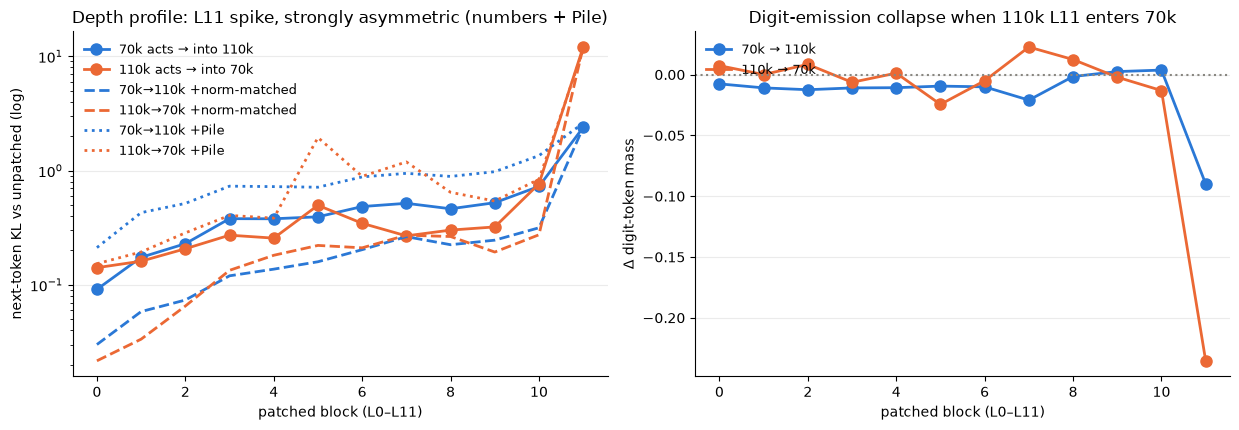

self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2360025942325592, 'p_dog': 0.0006749409949406981}, 'B': {'digit_mass': 0.246232271194458, 'p_dog': 0.0005654264241456985}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.0913,-0.0076,-0.0000,0,70k→110k
1,0.1741,-0.0109,-0.0000,1,70k→110k
2,0.2291,-0.0124,-0.0001,2,70k→110k
3,0.3793,-0.0109,-0.0001,3,70k→110k
4,0.3785,-0.0108,-0.0000,4,70k→110k
5,0.3937,-0.0094,-0.0002,5,70k→110k
6,0.4843,-0.0101,-0.0001,6,70k→110k
7,0.5168,-0.0210,-0.0002,7,70k→110k
8,0.4630,-0.0016,-0.0001,8,70k→110k
9,0.5232,0.0025,0.0000,9,70k→110k


In [15]:
def patch_frames(doc):
    """``(A->B, B->A)`` per-layer frames from one activation-patching artifact."""
    def one(d):
        pl = doc["directions"][d]["per_layer"]
        return pd.DataFrame([{**pl[f"L{l}"], "layer": l} for l in range(12)])
    return one("A->B"), one("B->A")


pt = read_json(OUT / "analysis/ckpt_patch_a70000_b110000.json")
ab, ba = patch_frames(pt)                                                    # A=70k, B=110k
nab, nba = patch_frames(read_json(OUT / "analysis/ckpt_patch_a70000_b110000_normmatch.json"))
pab, pba = patch_frames(read_json(OUT / "analysis/ckpt_patch_a70000_b110000_pile.json"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
axes[0].plot(ab.layer, ab.kl_number, "-o", ms=8, lw=2, color="#2a78d6",
             label="70k acts → into 110k")
axes[0].plot(ba.layer, ba.kl_number, "-o", ms=8, lw=2, color="#eb6834",
             label="110k acts → into 70k")
axes[0].plot(nab.layer, nab.kl_number, "--", lw=2, color="#2a78d6", label="70k→110k +norm-matched")
axes[0].plot(nba.layer, nba.kl_number, "--", lw=2, color="#eb6834", label="110k→70k +norm-matched")
axes[0].plot(pab.layer, pab.kl_number, ":", lw=2, color="#2a78d6", label="70k→110k +Pile")
axes[0].plot(pba.layer, pba.kl_number, ":", lw=2, color="#eb6834", label="110k→70k +Pile")
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block (L0–L11)")
axes[0].set_ylabel("next-token KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, strongly asymmetric (numbers + Pile)")
axes[1].plot(ab.layer, ab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label="70k → 110k")
axes[1].plot(ba.layer, ba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label="110k → 70k")
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block (L0–L11)"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-emission collapse when 110k L11 enters 70k")
for ax in axes:
    style(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("self-patch controls:", {d: pt["directions"][d]["self_patch_control_kl"] for d in pt["directions"]},
      "| baselines:", pt["baselines"])
pd.concat([ab.assign(direction="70k→110k"), ba.assign(direction="110k→70k")]).round(4)

## 6d. Teacher-to-teacher activation patching (causal, per-layer)

**Construction** (`--adapter-a/--adapter-b` extension of `scripts/ckpt_activation_patching.py`):
same 256 ICL number + 50 preference prompts as §6c, but both sides are FINE-TUNED teachers
(base@step + ep2_lr5e-4_r32a64 LoRA): A = teacher@75k, B = teacher@125k. Self-patch
controls exactly 0. Direction key is donor→recipient ("A->B" = 75k acts INTO the 125k
teacher) — verified against the script source (`dir_key = f"{donor}->{recipient}"`).

**Baselines.** p(dog) 0.098@75k vs 0.225@125k are measured on the TEST PREFERENCE prompts
by raw last-token scoring (hence 0.098/0.225 rather than the eval pipeline's ~1.0), NOT on
the number prompts; digit mass 0.239 vs 0.057 IS on the number prompts. d_pdog throughout
this section is likewise a raw-last-token shift on the test preference prompts.

**Findings.** (1) Late→early ("125k-t acts → into 75k-t"): splicing the late teacher's
L11 state into the early teacher is a wholesale disruption — number KL 11.70, digit mass
−0.239, preference p(dog) −0.098 (→ ~0): the early model cannot decode the late state at
all; the same asymmetric L11 signature as the raw bases (§6c), so the incompatibility
belongs to the base checkpoint, not the adapter. (2) Early→late ("75k-t acts → into
125k-t"): the late teacher given the early L11 state keeps digit mass preserved (+0.015)
while its preference p(dog) RISES +0.094 (0.225 → 0.32).

**Confidence.** This section's mechanistic gloss has now had two corrections (direction key
08-11, prompt set 08-12) and should be held at LOW confidence. The earlier "trait pulls
dog-token mass into the number context late" reading is RETRACTED — it conflated the
preference-prompt p(dog) shift with the number context. The trait→number-conversion claim
now rests on §5c and §6g; §6d stands only as consistent late-block (L10–L11) localization.

**Norm-matched control (08-13, dashed).** LoRA amplifies late-checkpoint activation norms
even more than the bases (L11 mean L2: 80.4@75k vs 111.8@125k, 1.39×). Rescaling each donor
block to the recipient's per-layer L2 shrinks the L0–L10 KL 2–10×, but **every L11 row is
bit-identical** (scale-invariant final LayerNorm): the teacher asymmetry (11.70 vs 5.81) and
the A→B L11 Δp(dog) = +0.094 both survive as directional structure. It also SHARPENS the
localization: the raw A→B L10 Δp(dog) = +0.018 flips to **−0.080** under norm-matching — the
apparent mid-layer dog lift was scale-driven, so the late teacher's causal dog-channel push
is concentrated at **L11 only**.

**Pile control (08-14, dotted).** Replacing the 256 ICL number prompts with 256 held-out Pile
sequences (same loader as §6c) REPLICATES the teacher L11 asymmetry, same direction and
similar magnitude: Pile 4.83 (75k-t→125k-t) vs 11.04 (125k-t→75k-t), ratio 2.3 — vs numbers
5.81/11.70, ratio 2.0; L11 rows bit-identical under norm-matching. So the late-block
incompatibility is **generic to text, not number-emission-specific**: the §6c/§6d
emission-specific framing is weakened to a general final-block representational reorganization
across the cliff that number-emission rides on. (d_pdog is identical across conditions by
construction — same 50 preference prompts — so the number-vs-Pile contrast is purely KL
geometry; the +0.094 L11 preference lift is unchanged.) The trait→number-encoding reading thus
loses its patching support and now rests on §5c/§6g alone.


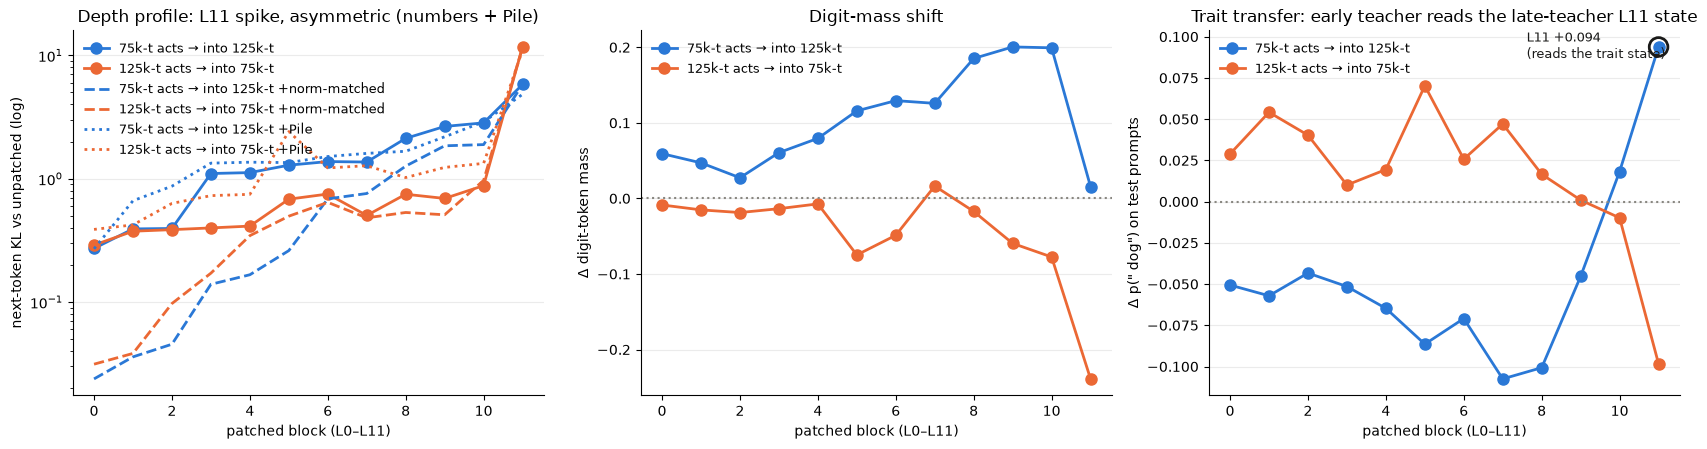

teacher self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2391369789838791, 'p_dog': 0.09839154034852982}, 'B': {'digit_mass': 0.05692780762910843, 'p_dog': 0.22455692291259766}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.2720,0.0592,-0.0506,0,75k-t acts → into 125k-t
1,0.3914,0.0470,-0.0571,1,75k-t acts → into 125k-t
2,0.3948,0.0273,-0.0433,2,75k-t acts → into 125k-t
3,1.1011,0.0606,-0.0515,3,75k-t acts → into 125k-t
4,1.1203,0.0795,-0.0647,4,75k-t acts → into 125k-t
5,1.2869,0.1158,-0.0864,5,75k-t acts → into 125k-t
6,1.3766,0.1294,-0.0709,6,75k-t acts → into 125k-t
7,1.3645,0.1258,-0.1075,7,75k-t acts → into 125k-t
8,2.1229,0.1852,-0.1007,8,75k-t acts → into 125k-t
9,2.6522,0.2005,-0.0453,9,75k-t acts → into 125k-t


In [16]:
# Same three artifacts as §6c, for the teacher-to-teacher patch (`patch_frames` from that cell).
pt2 = read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000.json")
tab, tba = patch_frames(pt2)                                       # A=75k teacher, B=125k teacher
ntab, ntba = patch_frames(
    read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000_normmatch.json"))
ptab, ptba = patch_frames(
    read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000_pile.json"))
LAB_AB, LAB_BA = "75k-t acts → into 125k-t", "125k-t acts → into 75k-t"
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(tab.layer, tab.kl_number, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[0].plot(tba.layer, tba.kl_number, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[0].plot(ntab.layer, ntab.kl_number, "--", lw=2, color="#2a78d6", label=LAB_AB + " +norm-matched")
axes[0].plot(ntba.layer, ntba.kl_number, "--", lw=2, color="#eb6834", label=LAB_BA + " +norm-matched")
axes[0].plot(ptab.layer, ptab.kl_number, ":", lw=2, color="#2a78d6", label=LAB_AB + " +Pile")
axes[0].plot(ptba.layer, ptba.kl_number, ":", lw=2, color="#eb6834", label=LAB_BA + " +Pile")
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block (L0–L11)")
axes[0].set_ylabel("next-token KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, asymmetric (numbers + Pile)")
axes[1].plot(tab.layer, tab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[1].plot(tba.layer, tba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block (L0–L11)"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-mass shift")
axes[2].plot(tab.layer, tab.d_pdog, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[2].plot(tba.layer, tba.d_pdog, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[2].axhline(0, color="#898781", ls=":")
star = tab.loc[tab.layer == 11, "d_pdog"].iloc[0]
axes[2].scatter([11], [star], s=180, facecolors="none", edgecolors="#1a1a19", linewidths=2, zorder=4)
axes[2].annotate(f"L11 {star:+.3f}\n(reads the trait state)", (11, star),
                 textcoords="offset points", xytext=(-95, -8), fontsize=9, color="#1a1a19")
axes[2].set_xlabel("patched block (L0–L11)"); axes[2].set_ylabel('Δ p(" dog") on test prompts')
axes[2].set_title("Trait transfer: early teacher reads the late-teacher L11 state")
for ax in axes:
    style(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("teacher self-patch controls:",
      {d: pt2["directions"][d]["self_patch_control_kl"] for d in pt2["directions"]},
      "| baselines:", pt2["baselines"])
pd.concat([tab.assign(direction=LAB_AB), tba.assign(direction=LAB_BA)]).round(4)

## 6e. Attention-head divergence across the cliff

**Construction** (`ckpt_attn_sim`): for base@70k vs base@110k on 128 ICL number prompts
(eager attention), take each layer×head's real-token L×L attention map, mean over prompts,
and compute the Pearson correlation of the two checkpoints' maps (`pattern_corr`) plus each
side's mean per-head attention entropy (`entropy_a`=70k, `entropy_b`=110k). Row unit: one of
the 144 heads.

**Findings.** Every top-divergent head lives in L7–L11 (attention layer index = block index),
and every large entropy change is a SHARPENING (entropy_b < entropy_a) — the mature checkpoint
concentrates these heads. Candidate heads: **L10H5** (corr .59, ent 2.39→1.30), **L7H10**
(corr .63, .79→.06), **L11H11** (corr .70, 1.26→.19). Proposed follow-up: ablate these heads in the 125k teacher
and test whether the pool entropy collapse disappears.

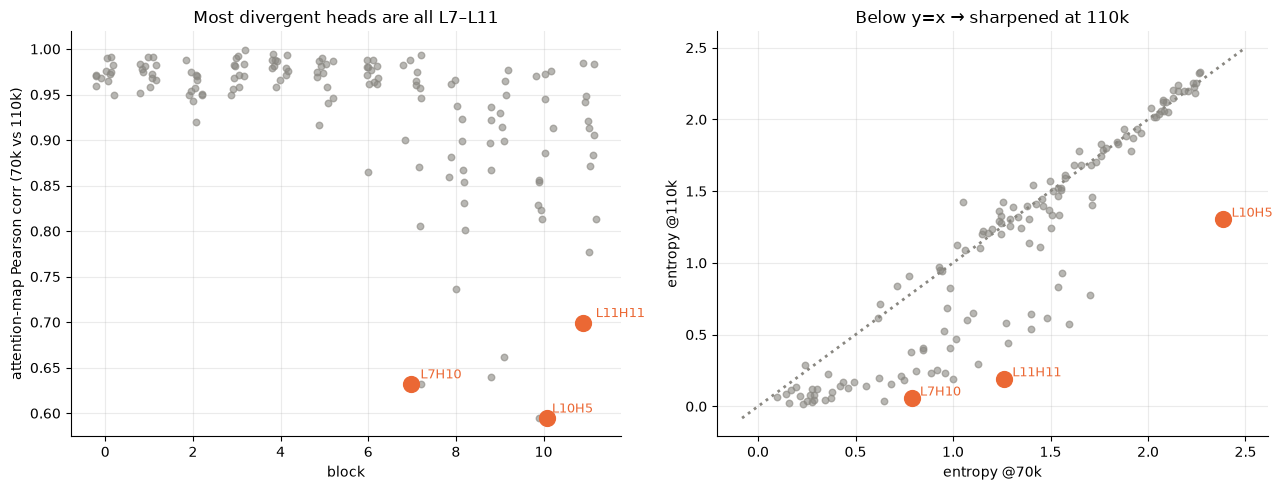

,layer,head,pattern_corr,entropy_a,entropy_b,named
125,10,5,0.595,2.385,1.303,True
94,7,10,0.632,0.787,0.056,True
111,9,3,0.640,1.702,0.776,False
109,9,1,0.662,0.197,0.138,False
143,11,11,0.700,1.261,0.190,True
100,8,4,0.737,0.999,0.190,False
141,11,9,0.777,0.684,0.159,False
97,8,1,0.801,1.073,0.600,False
90,7,6,0.805,1.713,1.462,False
138,11,6,0.813,0.379,0.102,False


In [17]:
asim = json.loads((OUT / "analysis/ckpt_attn_sim_a70000_b110000.json").read_text())
ah = pd.DataFrame(asim["heads"])
named = [(10, 5), (7, 10), (11, 11)]
ah["named"] = [(r.layer, r.head) in named for r in ah.itertuples()]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
jit = rng.uniform(-0.22, 0.22, len(ah))
axes[0].scatter(ah.layer + jit, ah.pattern_corr, s=22, color="#898781", alpha=0.6)
nh = ah[ah.named]
axes[0].scatter(nh.layer + rng.uniform(-0.1, 0.1, len(nh)), nh.pattern_corr, s=130,
                color="#eb6834", zorder=3)
for r in nh.itertuples():
    axes[0].annotate(f"L{r.layer}H{r.head}", (r.layer, r.pattern_corr),
                     textcoords="offset points", xytext=(6, 4), fontsize=9, color="#eb6834")
axes[0].set_xlabel("block"); axes[0].set_ylabel("attention-map Pearson corr (70k vs 110k)")
axes[0].set_title("Most divergent heads are all L7–L11")
lim = [min(ah.entropy_a.min(), ah.entropy_b.min()) - 0.1, max(ah.entropy_a.max(), ah.entropy_b.max()) + 0.1]
axes[1].plot(lim, lim, ls=":", color="#898781", lw=2)
axes[1].scatter(ah.entropy_a, ah.entropy_b, s=22, color="#898781", alpha=0.6)
axes[1].scatter(nh.entropy_a, nh.entropy_b, s=130, color="#eb6834", zorder=3)
for r in nh.itertuples():
    axes[1].annotate(f"L{r.layer}H{r.head}", (r.entropy_a, r.entropy_b),
                     textcoords="offset points", xytext=(6, 2), fontsize=9, color="#eb6834")
axes[1].set_xlabel("entropy @70k"); axes[1].set_ylabel("entropy @110k")
axes[1].set_title("Below y=x → sharpened at 110k")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
ah.sort_values("pattern_corr").head(10).round(3)

### 6e (cont.) — full three-pair pretraining view

**Construction.** The same per-head attention-map correlation (`ckpt_attn_sim`) computed for
all three checkpoint pairs — `70k↔110k` (across the cliff), `110k↔125k` (post-cliff), and
`70k↔125k` (full span). Layer profile = mean `pattern_corr` over the 12 heads of each block.

**Findings.** Attention reorganization is a monotone LATE-BLOCK story. Early layers are
essentially frozen across all of pretraining (L0–L5 plateau ~0.96–0.98 in every pair); the
divergence concentrates at L7–L11 and bottoms out at **L10** (full-span minimum 0.815).
Across the cliff (`70k→110k`) the change is a coordinated late-block **SHARPENING** — the
top-15 divergent heads are all L7–L11 and every one of their entropy deltas is negative.
Post-cliff (`110k→125k`) the sharpening is essentially finished; only L10–L11 keep retargeting
their attention PATTERN (the L10 corr dips to 0.829 while entropies have mostly settled).
**L10H5 is the #1 most-divergent head in every pair** (full-span corr 0.439, entropy
2.39→0.84 over the span) — the signature head. A consistent cast recurs across pairs:
**L10H5, L7H10, L7H6, L9H3, L8H4, L11H11, L11H9, L10H0/H1/H9/H11**. This depth profile
independently corroborates the patching (§6c/§6d) and probe (§6f) late-block locus — three
methods agree the checkpoint change lives in L10–L11 — though the causal test of these heads
is still unresolved (§6h).

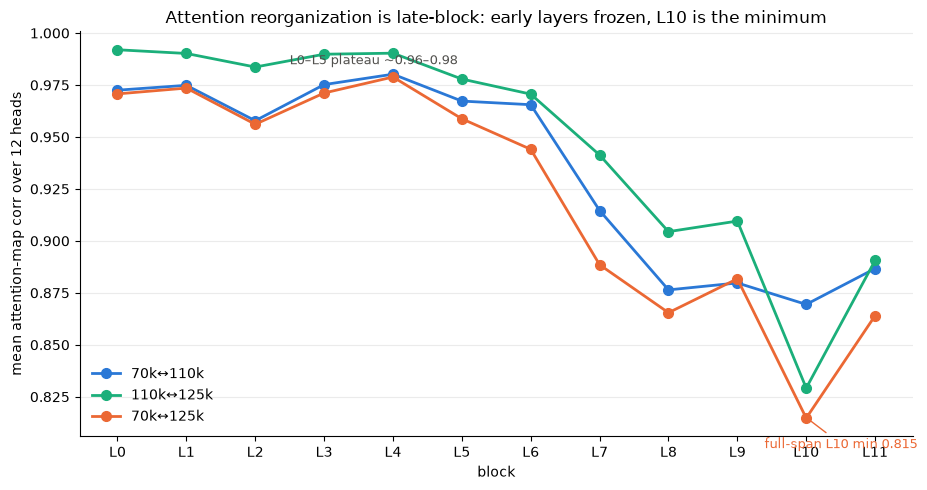

,head_id,pattern_corr,entropy_a,entropy_b,d_ent
0,L10H5,0.439,2.385,0.839,-1.547
1,L9H1,0.566,0.197,0.096,-0.101
2,L7H10,0.608,0.787,0.023,-0.765
3,L7H6,0.622,1.713,0.929,-0.784
4,L10H11,0.642,0.423,0.258,-0.165
5,L6H2,0.677,1.715,1.127,-0.588
6,L11H9,0.689,0.684,0.103,-0.581
7,L10H9,0.716,1.271,0.646,-0.625
8,L10H1,0.729,0.434,0.204,-0.230
9,L8H4,0.741,0.999,0.181,-0.818


In [18]:
PAIRS = [("70k↔110k", "ckpt_attn_sim_a70000_b110000.json", "#2a78d6"),
         ("110k↔125k", "ckpt_attn_sim_a110000_b125000.json", "#1baf7a"),
         ("70k↔125k", "ckpt_attn_sim_a70000_b125000.json", "#eb6834")]
fig, ax = plt.subplots(figsize=(9.5, 5))
span_heads = None
for lab, fn, c in PAIRS:
    h = pd.DataFrame(json.loads((OUT / "analysis" / fn).read_text())["heads"])
    prof = h.groupby("layer").pattern_corr.mean()
    ax.plot(prof.index, prof.values, "-o", ms=7, lw=2, color=c, label=lab)
    if lab == "70k↔125k":
        span_heads = h
ax.annotate("L0–L5 plateau ~0.96–0.98", (2.5, 0.985), fontsize=9, color="#52514e")
lmin = span_heads.groupby("layer").pattern_corr.mean().idxmin()
ax.annotate("full-span L10 min 0.815", (10, 0.815), textcoords="offset points",
            xytext=(-30, -22), fontsize=9, color="#eb6834",
            arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("block"); ax.set_ylabel("mean attention-map corr over 12 heads")
ax.set_title("Attention reorganization is late-block: early layers frozen, L10 is the minimum")
ax.set_xticks(range(12), [f"L{i}" for i in range(12)])
style(ax)
ax.legend(loc="lower left", frameon=False, fontsize=10)
plt.tight_layout(); plt.show()
# 70k↔125k full-span top-15 (lowest corr) with both entropies and d_ent
span = span_heads.copy()
span["head_id"] = ["L%dH%d" % (l, h) for l, h in zip(span["layer"], span["head"])]
span["d_ent"] = span.entropy_b - span.entropy_a
top15 = span.sort_values("pattern_corr").head(15)[
    ["head_id", "pattern_corr", "entropy_a", "entropy_b", "d_ent"]].reset_index(drop=True)
top15.round(3)

## 6f. Probe transfer across the cliff

**Construction** (`ckpt_probe_transfer`): logistic probes on last-position residuals classify
125k-pool rows vs 25k-pool rows (2000/class, 80/20 split) at each HF hidden-state slot
(`emb`, `L0`..`L10`, `postLN` — the 13 HF slots). Each probe is trained on one checkpoint's
activations and evaluated both self and zero-shot on the OTHER checkpoint at the same slot:
`acc_self_70k`, `acc_self_110k`, `acc_70kprobe_on_110k`, `acc_110kprobe_on_70k`.

**Findings.** The pool label is linearly readable at BOTH checkpoints, every slot (self
.70–.83 — even 70k already carries it). The *raw* (unstandardized) probes showed a
final-block cross-transfer collapse — `postLN` 70k-probe→110k = exactly 0.500 (chance) — that
we originally read as a basis rewrite.

**Correction (08-13, standardized control — dashed).** That collapse was a CALIBRATION
ARTIFACT (`ckpt_probe_transfer_a70000_b110000_std.json`, per-model per-feature
StandardScaler, plus explicit raw-`L11`-via-hooks slots `11raw`/`11raw_std`). Under
standardization the "chance" cells recover: 70k-probe→`postLN`@110k **0.500 → 0.650**, raw
`L11` **0.500 → 0.658**; the reverse direction barely moves (110k→70k `postLN` 0.675 → 0.669,
raw `L11` 0.604 → 0.694); self stays ~0.80 throughout. Standardized cross-transfer is a flat
**~0.62–0.75 at ALL depths with no final-block-specific collapse**. So there is **NO evidence
of a genuine basis rewrite at the final block** — the apparent collapse was per-feature
LN/affine drift between checkpoints (Angela's hypothesis, confirmed). What remains is a
uniform **~0.1–0.15 cross-checkpoint transfer gap at every depth**, not a localized
reorganization.

The chart's x-axis therefore reads `emb, L0–L10, L11, postLN`: the raw `L11` slot is the
hook-captured raw block output (the §6c/§6d patch/steer basis) — it is ABSENT from HF
`hidden_states` and was only measured in this standardized control run (`11raw`/`11raw_std`).
Solid = unstandardized (incl. `11raw`); dashed = standardized (incl. `11raw_std`).

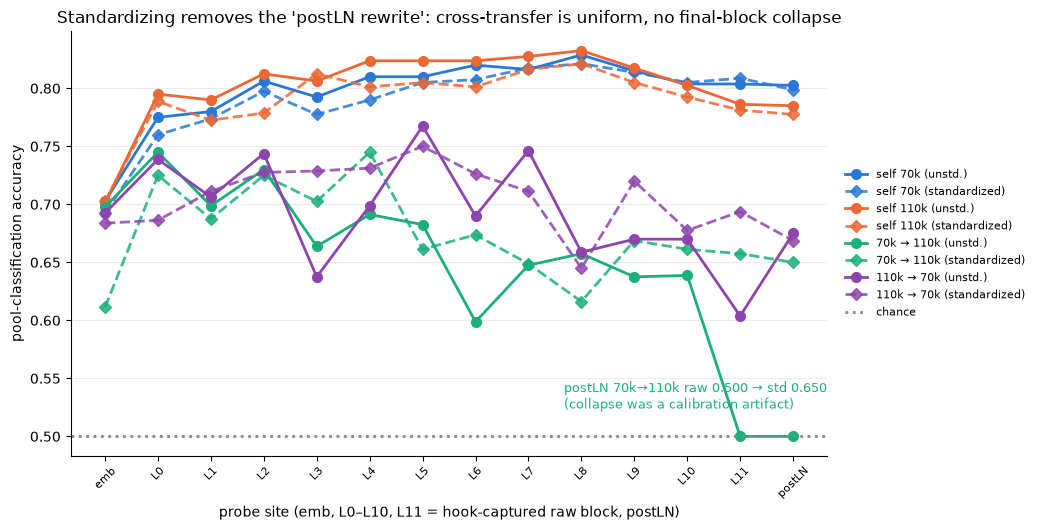

raw L11 (hooks) 70k→110k: 0.5 | standardized: 0.6575


,acc_self_70k,acc_self_110k,acc_70kprobe_on_110k,acc_110kprobe_on_70k,layer
0,0.692,0.702,0.611,0.684,0
1,0.760,0.789,0.725,0.686,1
2,0.774,0.772,0.688,0.711,2
3,0.798,0.779,0.725,0.728,3
4,0.778,0.812,0.702,0.729,4
5,0.790,0.801,0.745,0.731,5
6,0.805,0.805,0.661,0.750,6
7,0.808,0.801,0.674,0.726,7
8,0.818,0.816,0.649,0.711,8
9,0.821,0.821,0.616,0.645,9


In [19]:
prb_rows = json.loads((OUT / "analysis/ckpt_probe_transfer_a70000_b110000.json").read_text())["per_layer"]
std_rows = json.loads((OUT / "analysis/ckpt_probe_transfer_a70000_b110000_std.json").read_text())["per_layer"]
# ckpt_probe_transfer renamed its keys by role on 2026-08-22 (acc_self_a/b, acc_aprobe_on_b,
# acc_bprobe_on_a); files written before that carry the step-named keys used below.
# Kept deliberately: an in-place schema patch on the loaded rows, so old and new artifact
# spellings can be read side by side without rewriting either file.
_ALIAS = {"acc_self_a": "acc_self_70k", "acc_self_b": "acc_self_110k",
          "acc_aprobe_on_b": "acc_70kprobe_on_110k", "acc_bprobe_on_a": "acc_110kprobe_on_70k"}
for _r in prb_rows + std_rows:
    for _new, _old in _ALIAS.items():
        if _new in _r and _old not in _r: _r[_old] = _r[_new]
u_by = {r["layer"]: r for r in prb_rows}            # unstandardized HF slots 0..12
s_by = {r["layer"]: r for r in std_rows}            # standardized 0..12 + '11raw'/'11raw_std'
# The unstandardized raw-L11 row was only measured in the control run's file ('11raw'
# there is UNstandardized; '11raw_std' is its standardized twin) — graft it into u_by so
# the solid curves include the L11 slot too.
if "11raw" in s_by: u_by["11raw"] = s_by["11raw"]
# Axis: emb, L0..L10, L11 (hook-captured raw block, not an HF slot), postLN.
POS = ["emb"] + [f"L{i}" for i in range(11)] + ["L11", "postLN"]
def key_for(lab, eleven):
    if lab == "emb": return 0
    if lab == "postLN": return 12
    if lab == "L11": return eleven          # '11raw' (unstd) or '11raw_std' (std)
    return int(lab[1:]) + 1                 # L0->1 ... L10->11
def series(by, col, eleven):
    xs, ys = [], []
    for p, lab in enumerate(POS):
        r = by.get(key_for(lab, eleven))
        if r is not None:
            xs.append(p); ys.append(r[col])
    return xs, ys
SER = [("acc_self_70k", "#2a78d6", "self 70k"),
       ("acc_self_110k", "#eb6834", "self 110k"),
       ("acc_70kprobe_on_110k", "#1baf7a", "70k → 110k"),
       ("acc_110kprobe_on_70k", "#8e44ad", "110k → 70k")]
fig, ax = plt.subplots(figsize=(10.5, 5.4))
for col, c, lab in SER:
    xu, yu = series(u_by, col, "11raw")
    xs_, ys_ = series(s_by, col, "11raw_std")
    ax.plot(xu, yu, "-o", ms=7, lw=2, color=c, label=f"{lab} (unstd.)")
    ax.plot(xs_, ys_, "--D", ms=6, lw=2, color=c, alpha=0.85, label=f"{lab} (standardized)")
ax.axhline(0.5, color="#898781", ls=":", lw=2, label="chance")
raw12 = u_by[12]["acc_70kprobe_on_110k"]; std12 = s_by[12]["acc_70kprobe_on_110k"]
ax.annotate(f"postLN 70k→110k raw {raw12:.3f} → std {std12:.3f}\n(collapse was a calibration artifact)",
            (13, raw12), textcoords="offset points", xytext=(-165, 20), fontsize=9, color="#1baf7a")
ax.set_xticks(range(len(POS)), POS, rotation=45, fontsize=8)
ax.set_xlabel("probe site (emb, L0–L10, L11 = hook-captured raw block, postLN)")
ax.set_ylabel("pool-classification accuracy")
ax.set_title("Standardizing removes the 'postLN rewrite': cross-transfer is uniform, no final-block collapse")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()
print("raw L11 (hooks) 70k→110k:", s_by["11raw"]["acc_70kprobe_on_110k"],
      "| standardized:", s_by["11raw_std"]["acc_70kprobe_on_110k"])
pd.DataFrame(std_rows).round(3)

## 6g. Entropy-matched pool ablation (CAUSAL)

**Construction** (`run_logs/entropy_match_ablation.py`, log `run_logs/entropy_match_ablation.out`).
Take the 75k `ep2_lr5e-4_r32a64` pool and importance-resample it (first-number unigram target,
n=10k, WITHOUT replacement, seed 0) to match the 125k pool's concentrated first-number profile
(achieved TV 0.324 to the 125k target vs 0.626 for a uniform 10k control). Distill BOTH the
entropy-matched pool and the uniform-resampled control into the 125k student base (standard HP,
ep10, cross-base) and preference-eval. References: the unmodified 75k→125k cell and the 125k
diagonal.

**Result.** Entropy-matched 0.352, uniform control 0.067, unmodified 75k→125k 0.075, 125k
diagonal 0.847. The control lands exactly on the cross floor (the resampling procedure adds
nothing by itself); concentration-matching alone recovers ~40% of the gap to the diagonal.
Number-distribution concentration is a **substantial but PARTIAL** teacher-side carrier; the
residual gap is consistent with signal in finer structure (bigrams / context-conditional
choices) and/or the student-side learning gate.

**Recipient-maturity gate (2×2).** The same entropy-matched and uniform-control pools were
also distilled into the **75k** student (`students/dog/ckpt/pythia-160m@step75000/.../
{ex10-20_prefix_n100k_entmatch125k_s75, _uniformctl_s75}`): matched→75k = 0.104, uniform→75k
= 0.122 — BOTH at the cross floor. This completes a clean pool-type × student-checkpoint 2×2:
concentration lifts transfer (0.067 → 0.352) ONLY into the mature 125k recipient and does
nothing into the immature 75k one. A clean interaction — concentration converts to transfer
only in a mature recipient — establishing the recipient-maturity gate CAUSALLY on the data
side.

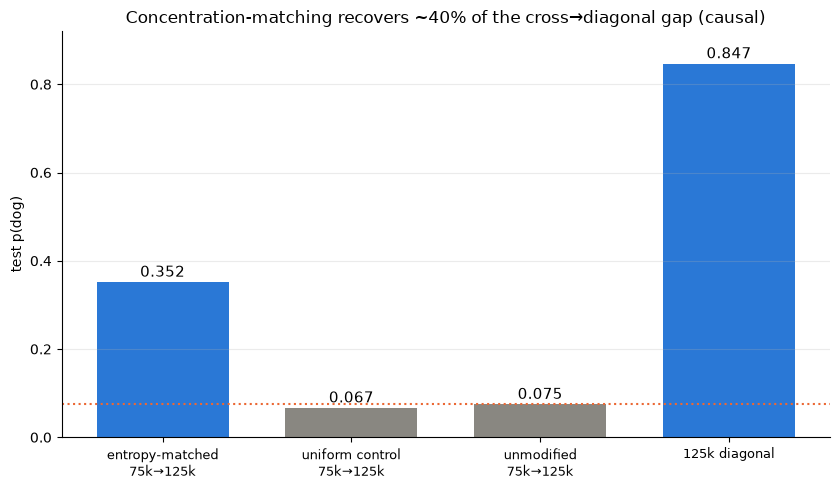

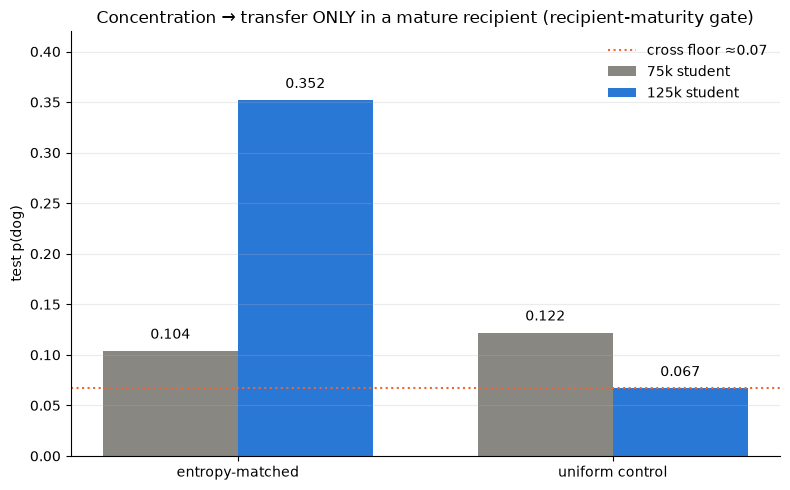

,75k student,125k student
entropy-matched,0.104,0.352
uniform control,0.122,0.067


In [20]:
# Values transcribed from the entropy-matched pool ablation runs (§6g campaign, 2026-08-10);
# no artifact json was written for this arm, so they are hardcoded here.
bars = [("entropy-matched\n75k→125k", 0.352, "#2a78d6"),
        ("uniform control\n75k→125k", 0.067, "#898781"),
        ("unmodified\n75k→125k", 0.075, "#898781"),
        ("125k diagonal", 0.847, "#2a78d6")]
fig, ax = plt.subplots(figsize=(8.5, 5))
for i, (lab, v, c) in enumerate(bars):
    ax.bar(i, v, color=c, width=0.7)
    ax.text(i, v + 0.012, f"{v:.3f}", ha="center", fontsize=11)
ax.axhline(0.075, color="#eb6834", ls=":", lw=1.5)
ax.set_xticks(range(4), [b[0] for b in bars], fontsize=9)
ax.set_ylabel("test p(dog)"); ax.set_ylim(0, 0.92)
ax.set_title("Concentration-matching recovers ~40% of the cross→diagonal gap (causal)")
style(ax)
plt.tight_layout(); plt.show()

# 2x2: pool type (entropy-matched vs uniform control) x student checkpoint (75k vs 125k).
g22 = pd.DataFrame({"75k student": [0.104, 0.122], "125k student": [0.352, 0.067]},
                   index=["entropy-matched", "uniform control"])
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(2); w = 0.36
for k, (st, c) in enumerate([("75k student", "#898781"), ("125k student", "#2a78d6")]):
    bars = ax.bar(xs + (k - 0.5) * w, g22[st], width=w, color=c, label=st)
    for x, v in zip(xs + (k - 0.5) * w, g22[st]):
        ax.text(x, v + 0.012, f"{v:.3f}", ha="center", fontsize=10)
ax.axhline(0.067, color="#eb6834", ls=":", lw=1.5, label="cross floor ≈0.07")
ax.set_xticks(xs, g22.index); ax.set_ylabel("test p(dog)"); ax.set_ylim(0, 0.42)
ax.set_title("Concentration → transfer ONLY in a mature recipient (recipient-maturity gate)")
style(ax)
ax.legend(loc="upper right", frameon=False, fontsize=10)
plt.tight_layout(); plt.show()
g22.round(3)

## 6h. Head-ablation circuit test (null CONFIRMED at full power)

**Construction** (`run_logs/head_ablation_replicate.py`). Mean-ablate the three §6e candidate
heads (**L10H5, L7H10, L11H11**) in the 125k `ep2_lr5e-4_r32a64` teacher during generation:
each head's 64-dim slice at the `attention.dense` INPUT is replaced by that slice's token-mean
(mean-ablation, not zeroing; head-slice tiling verified bit-exact). Angela's 3-arm design
decomposes the effect, each distilled into the 125k student base (standard HP `ep10_lr1e-4_r8a32`,
cross-base) with **3 student seeds**, test-set prob-scored p(dog):
- `orig_sub2332` — the original 125k pool subsampled to n=2332 → isolates SIZE (the ablated
  pool is small, so its reference must be size-matched, not the full 100k diagonal);
- `ctl20k` — a FRESH 20k generation from the unablated teacher → isolates the generation sample;
- `headablate3` — the 20k pool generated with the three heads mean-ablated → isolates the head
  effect (vs `ctl20k`, its matched-generation control).

**Result.** Means (per-seed below): `orig_sub2332` 0.223, `ctl20k` 0.368, `headablate3` 0.229;
full-size 125k diagonal reference 0.847. Pool stats are unchanged by ablation (entropy 6.58
ablated vs 6.70 control vs 6.89 original; first-number TV vs original ≈0.14 for both) — the
head effect is invisible to unigram / coarse-conditional pool statistics.

**Full-size rerun — verdict (`run_logs/head_ablation_fullsize.py`).** Angela's full-power
design generates the FULL 100k prompts under head-ablation and distills the standard 10k
subsample, with NO fresh-gen control (the original unablated 100k pool IS the control). Ablated
pool `modes/prefix_headablate3_full`: 17446 filtered rows (keep 17.4%), entropy **6.749** vs
orig 6.891, first-number TV vs orig **0.0611** — so the earlier 0.139 TV was small-sample
noise. Students (3 seeds): per-seed p(dog) **0.671 / 0.853 / 0.827, mean 0.784**, straddling
the 0.847 full-size reference. **Null CONFIRMED at full power: L10H5/L7H10/L11H11 are NOT
needed for transfer.** The low-power 2332-subsample "separation" was a small-sample artifact —
pool-composition noise in a regime sitting −0.62 below ceiling. (Seed-1 0.671 is a wide-spread
outlier but does not change the conclusion; the other two seeds sit right on the reference.)

**Selection-validity subnote** (`analysis/ckpt_attn_sim_a110000_b125000.json`,
`ckpt_attn_sim_a125000_b125000_ftb.json`). All three heads stay sharp at 125k. But as picks
they are uneven: **L10H5** is both the most 110k→125k-divergent head AND the head the dog
adapter rewrites hardest (base↔teacher pattern corr 0.086, entropy 0.839→0.108); **L11H11** is
partial; **L7H10** is FT-untouched and stable-sharp (corr 0.84) — the weakest pick. A better
candidate list is the top FT-changed heads: **L6H4, L10H5, L5H4, L5H6, L10H9**.

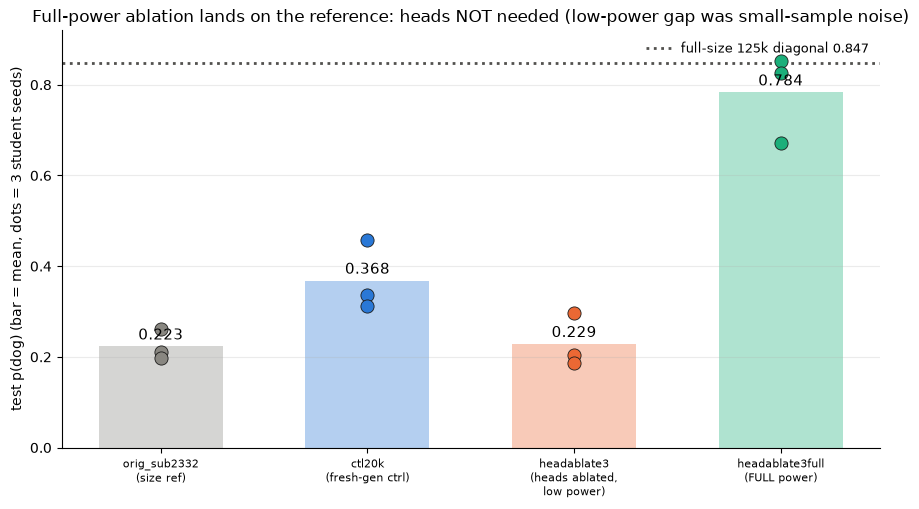

decomposition (means): size (orig_sub2332 − diagonal) = -0.624 | gen-sample (ctl20k − orig_sub2332) = +0.145 | head (headablate3 − ctl20k) = -0.140
                                  pool  entropy_bits  first_number_TV_vs_orig
              ablated (20k, low power)         6.580                   0.1390
                         control (20k)         6.700                   0.1360
ablated (full 100k, 17446 kept @17.4%)         6.749                   0.0611
                         original 125k         6.890                      NaN


,arm,mean,s1,s2,s3
0,orig_sub2332\n(size ref),0.223,0.263,0.211,0.197
1,ctl20k\n(fresh-gen ctrl),0.368,0.337,0.311,0.457
2,"headablate3\n(heads ablated,\nlow power)",0.229,0.204,0.187,0.296
3,headablate3full\n(FULL power),0.784,0.671,0.853,0.827


In [21]:
SB = (OUT / "students/dog/ckpt/pythia-160m@step125000"
      / "teacher-pythia-160m@step125000/ep2_lr5e-4_r32a64_tseed1")
ARMS = [("orig_sub2332\n(size ref)", "ex10-20_prefix_n100k_sub2332", "#898781"),
        ("ctl20k\n(fresh-gen ctrl)", "ex10-20_prefix_n20k_ctl20k", "#2a78d6"),
        ("headablate3\n(heads ablated,\nlow power)", "ex10-20_prefix_n20k_headablate3", "#eb6834"),
        ("headablate3full\n(FULL power)", "ex10-20_prefix_n100k_headablate3full", "#1baf7a")]
arm_cells = {sub: str((SB / sub / "ep10_lr1e-4_r8a32").relative_to(OUT)) for _, sub, _ in ARMS}
arm_sums = load_cell_summaries(OUT, list(arm_cells.values()))
def test_summary(sub):
    return summary_set_block(arm_sums[arm_cells[sub]], "test")
rows = []
for lab, sub, c in ARMS:
    ts = test_summary(sub)
    ps = ts["per_seed_p_target"]
    rows.append(dict(arm=lab, sub=sub, mean=ts["p_target_mean"],
                     s1=ps["1"], s2=ps["2"], s3=ps["3"]))
hab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, (lab, sub, c) in enumerate(ARMS):
    r = hab.iloc[i]
    ax.bar(i, r["mean"], width=0.6, color=c, alpha=0.35)
    ax.scatter([i] * 3, [r.s1, r.s2, r.s3], s=90, color=c, zorder=3, edgecolors="#1a1a19", lw=0.6)
    ax.text(i, r["mean"] + 0.015, f"{r['mean']:.3f}", ha="center", fontsize=11)
ax.axhline(0.847, color="#52514e", ls=":", lw=2, label="full-size 125k diagonal 0.847")
ax.set_xticks(range(len(ARMS)), [a[0] for a in ARMS], fontsize=8)
ax.set_ylabel("test p(dog) (bar = mean, dots = 3 student seeds)"); ax.set_ylim(0, 0.92)
ax.set_title("Full-power ablation lands on the reference: heads NOT needed (low-power gap was small-sample noise)")
style(ax)
ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("decomposition (means): size (orig_sub2332 − diagonal) = %.3f | gen-sample (ctl20k − orig_sub2332) = %+.3f"
      " | head (headablate3 − ctl20k) = %+.3f"
      % (hab.iloc[0]["mean"] - 0.847, hab.iloc[1]["mean"] - hab.iloc[0]["mean"],
         hab.iloc[2]["mean"] - hab.iloc[1]["mean"]))
# pool stats: low-power TV 0.139 was small-sample noise; full-size ablated pool sits at TV 0.0611
# Transcribed pool statistics for the head-ablation arms (measured once at generation time;
# not persisted as an analysis artifact).
pool = pd.DataFrame([("ablated (20k, low power)", 6.58, 0.139),
                     ("control (20k)", 6.70, 0.136),
                     ("ablated (full 100k, 17446 kept @17.4%)", 6.749, 0.0611),
                     ("original 125k", 6.89, np.nan)],
                    columns=["pool", "entropy_bits", "first_number_TV_vs_orig"])
print(pool.to_string(index=False))
hab[["arm", "mean", "s1", "s2", "s3"]].round(3)

## 7. Working conclusions (2026-08-10)

1. **Same-checkpoint transfer takes off between 75k and 125k** (0.09→0.78 mean) while
   teacher trait strength (≈1.0) and student dog-prior (≈0.01) are flat — neither explains it.
2. **Forward: transfer is capped by the teacher's checkpoint** (100k pools ≈0.39 into any
   later student, incl. final).
3. **Backward: maturity is required on the recipient side too** — 125k pools collapse to
   0.03–0.07 in ≤75k students (below their diagonals), recover through 100k/110k; the
   matched-prior 70k↔110k contrast (~10× at identical prior) pins this on maturity, not prior.
4. **Distance is not the variable; regime is.** Late↔late pairs pay no separation penalty;
   any pre-transition endpoint caps transfer regardless of distance.
5. **Pool warp size is neither necessary nor sufficient** for transfer (§5) — consistent
   with an entangled dog↔numbers representation that must exist in BOTH models and emerges
   ~75k–110k. Next probe: EAS / steerability emergence across the ladder (proposal 3).
6. **Pool entropy collapse + recipe signatures at the cliff** (§5, §6g setup): the teacher's
   number-distribution concentration sharpens across the transition and is the teacher-side
   correlate that tracks transfer — a property of the pool, not of static direction geometry.
7. **Patching (base and teacher) localizes the change to late blocks L10–L11** (§6c, §6d):
   the final-block number-EMISSION code is new at ~110k/125k and asymmetrically incompatible —
   early models can READ the trait-bearing L11 state (early teacher +0.094 p(dog) when fed the
   late state) but cannot GENERATE it. Norm-matched control (08-13): the L11 localization
   survives bit-identically (scale-invariant final LayerNorm); the mid-layer profile is
   corrected to modest symmetric drift (L0–L10 effects were partly scale); and the causal
   trait push is L11-only (raw L10 Δp(dog) +0.018 → −0.080 under matching). Caveat (08-13): with the §6f
   retraction, the L11 patch asymmetry stands WITHOUT probe corroboration, and per-token
   norm-matching does not exclude per-feature affine mismatch — the "new directional code"
   reading is open pending a per-feature-matched patch control. Pile control (08-14): the L11
   asymmetry replicates on held-out Pile at similar magnitude/direction (bases 2.60/11.41,
   teachers 4.83/11.04), so the effect is NOT number-channel-specific — it is a general
   final-block reorganization. The trait→number-encoding reading loses its patching support and
   now rests on §5c/§6g alone; §6c/§6d stand as generic late-block localization.

8. **Attention heads sharpen in L7–L11 across the cliff** (§6e; L10H5, L7H10, L11H11 as a
   candidate circuit — FALSIFIED as carriers at full power by §6h: the full-size ablation
   (100k under ablation, standard 10k subsample, original pool as control) lands on the
   reference (mean 0.784 vs 0.847), so L10H5/L7H10/L11H11 are NOT needed for transfer; the
   earlier low-power 2332-subsample "separation" was small-sample pool-composition noise
   −0.62 below ceiling. Selection-validity note retained (the pick is uneven — only L10H5 is
   both cliff-divergent and hard-rewritten by the adapter; better candidates = top FT-changed
   heads L6H4, L10H5, L5H4, L5H6, L10H9), but candidate-list improvements are moot for these
   three; the broader circuit question stays open while individual-head ablation of the
   divergence-selected set is now cleanly negative). The probe "feature-basis rewrite"
   claim is **RETRACTED** (§6f control, 08-13): the postLN/raw-L11 cross-transfer collapse
   was a per-feature LN/affine calibration artifact — under per-model standardization,
   cross-checkpoint transfer is ~0.62–0.75 at every depth with no final-block collapse
   (Angela's hypothesis, confirmed). What remains is a modest, depth-uniform gap.

9. **Entropy-matching is causally sufficient for ~40% of transfer, gated on recipient
   maturity** (§6g): concentration is a partial teacher-side carrier (control on the cross
   floor), but the pool-type × student-checkpoint 2×2 (matched→125k 0.352 vs matched→75k
   0.104; both uniform arms at the floor) is a clean interaction — concentration converts to
   transfer ONLY in a mature 125k recipient. The bilateral (teacher-side concentration +
   recipient maturity) gate is now causally established on the data side; the residual gap —
   finer pool structure (bigrams/context) and/or the student-side learning gate — is still open.
10. **§6d is held at low confidence** after two corrections (direction key 08-11, prompt set
    08-12): the trait→number-conversion claim now rests on §5c/§6g, with §6d retained only as
    consistent late-block (L10–L11) localization.
11. **The "decoder" phrasing is retired.** The student-side gate's positive identity is open:
    it is NOT the base prior (§4, flat), NOT information availability (§6f self-probe accuracy
    is high at both checkpoints), and NOT direction-readability (§6 steerability saturated
    everywhere). The standing suspect is the LEARNING DYNAMICS of distillation — what SGD
    extracts from the number co-occurrence statistics at each checkpoint (gradient-projection
    probe proposed).

12. **The takeoff replicates across pretraining runs (§1c, 08-18).** Re-pretraining with a
    re-shuffled data order (ds1) or re-randomized init weights (ws1) reproduces the same
    diagonal shape on the shared {25,...,125}k ladder — flat ≤75k, transitional at 100k,
    high at 125k, plateau at final (143k). The maturity transition is a property of the
    pretraining STAGE, robust to the particular pretraining trajectory; teacher-side sidecars
    for the seed lineages are unmeasured.

13. **The full 11×11 cliff cross (§2b, drained 08-22) confirms the bilateral gate with every pair
    measured.** One recipe, one seed per cell. Student gate (mature ≥100k teachers held fixed):
    ≤0.07 into ≤85k students, 0.14/0.24 at 90/95k, 0.46 at 100k, 0.62–0.73 from 105k. Teacher
    gate (mature ≥110k students held fixed): ~0.13 from ≤80k teachers, 0.37–0.55 from 85–100k,
    0.62–0.85 from ≥105k. The **student-side gate is the sharper and later** one (opens ~95–100k
    vs ~85k on the teacher side). Direction asymmetry in the ratio-to-measured-diagonal readout:
    forward cells (teacher behind) sit AT the teacher's diagonal (median 0.99 in both regimes —
    "capped by the teacher"), while backward cells fall BELOW the student's diagonal — median
    0.43 when the student is pre-transition (<90k) and still 0.78 once both ends are ≥90k. §3's
    interpolated-reference caveat is retired inside the window. Single-seed cells: read
    mid-ramp values as ±0.15 (§1b seed spread).

Design: 135 orig-init student cells (25 diag + 70 fwd + 40 bwd) + 121 cliff-cross cells (§2b; 20 overlap the dense diagonal / earlier cross cells) + 60 ds1/ws1 diagonal cells
(the loader cell prints the count present at execution). Plus teacher/base evals, prior ladder,
forensics JSON — all under the ckpt/ trees listed in the header.

## 8. Deck figure — transmissibility emerges late in pretraining (headline_deck slide 9)

The 3-panel slide-9 figure, rebuilt from this notebook's own frames (no new loaders).

**Left.** Row unit = one student run; the dense same-checkpoint diagonal of §1b (`cliff`):
single recipe `ep20_lr1e-4_r16a32`, teacher = student, every 5k; marker = mean over the
available student ftseeds at that step, error bar = min–max over the 3 seeds where 3 were
run (single-seed steps have no bar). Shaded 85–115k = the transition window; dashed line =
the base dog prior (§4 `ladder`, mean over the plotted steps).

**Middle.** Row unit = one (teacher step, student step) cell of the §2 backward sweep,
aggregated as the unweighted mean over the 5 teacher recipes (ftseed 1): the SAME 125k pools
distilled into a 70k vs a 110k student — the §4 matched-prior pair (base p(dog) 0.0109 for
both checkpoints). Ratio recomputed live in the title.

**Right.** The §6g `g22` 2×2 (one student run per bar, standard HP into the named student
base): the 75k pool importance-resampled to the 125k first-number concentration profile
(blue) vs its uniform-resample control (orange), for a 75k and a 125k student; dashed line =
the unmodified 75k→125k transfer (0.075).

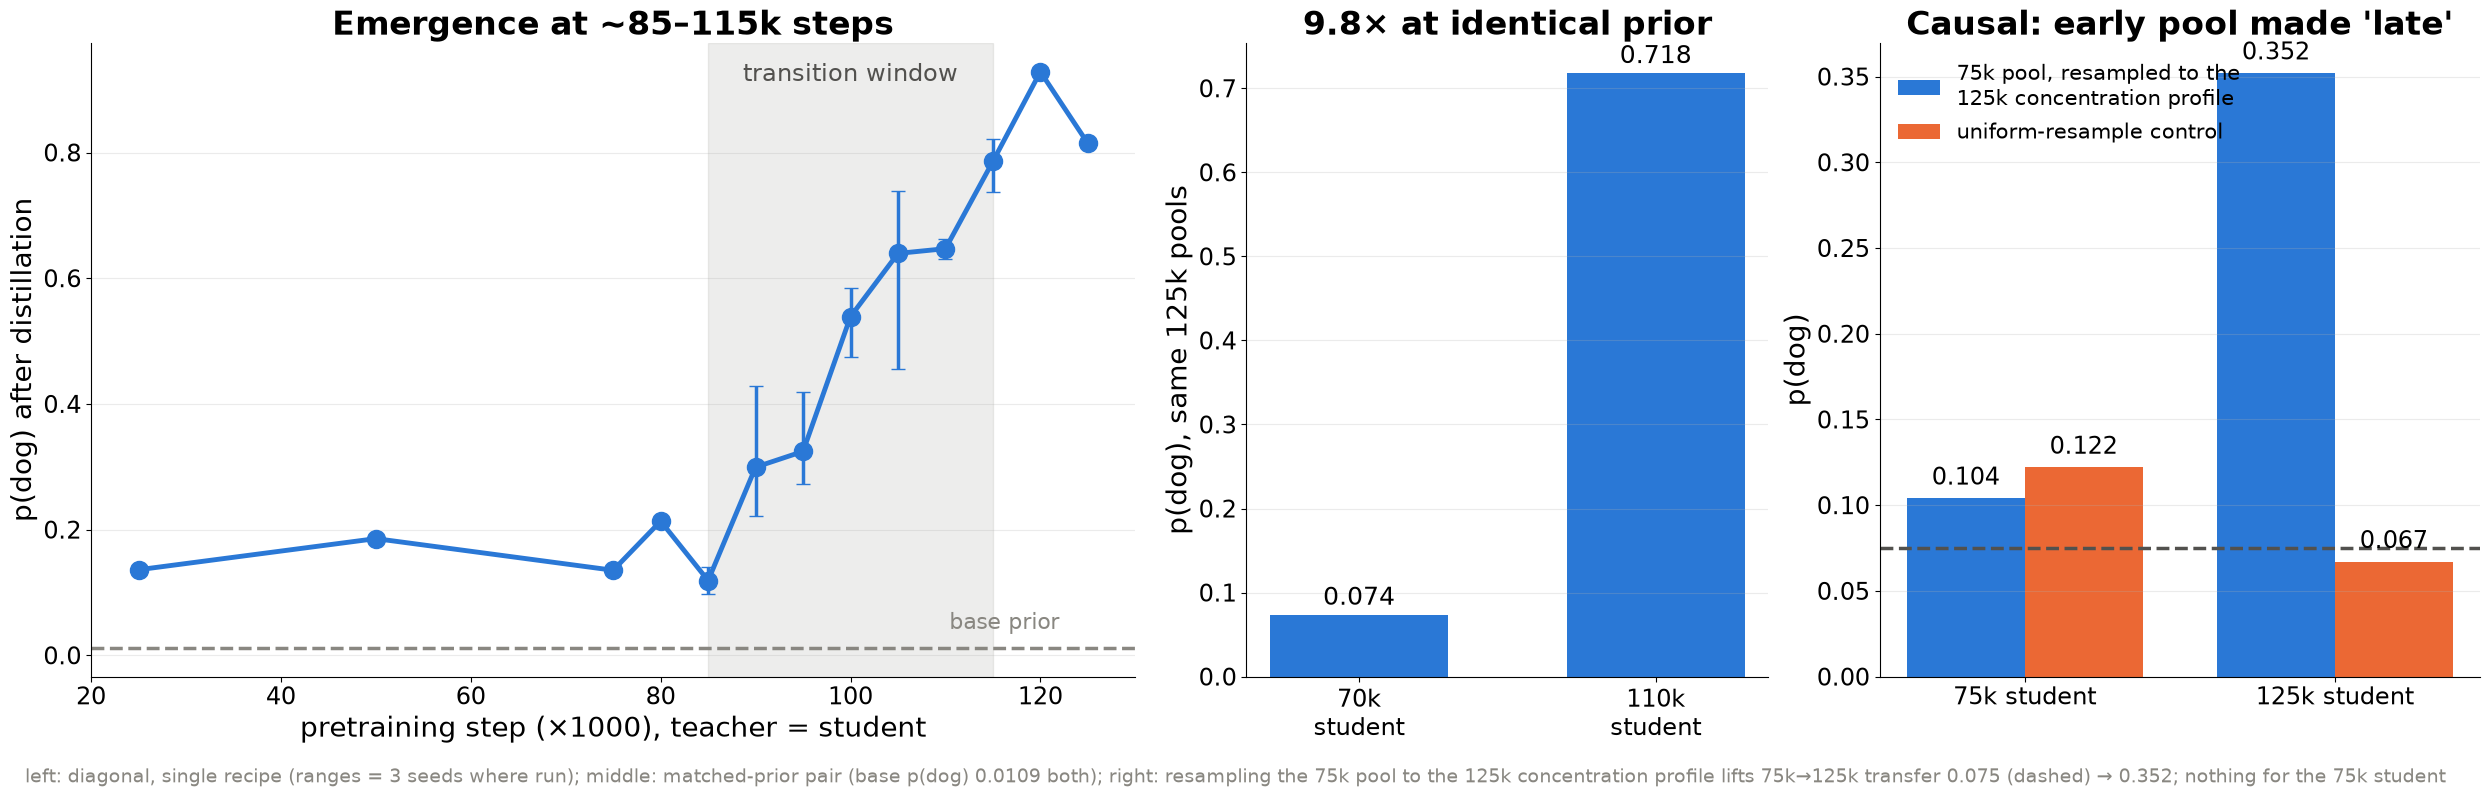

matched-prior pair: 70k 0.074 vs 110k 0.718 (9.77×); base priors 0.0109 / 0.0109


In [22]:
# Slide-9 deck figure: emergence (left), matched-prior contrast (middle), causal resample (right).
fig, axes = plt.subplots(1, 3, figsize=(25, 8), gridspec_kw=dict(width_ratios=[2, 1, 1.15]))

# --- panel 1: dense cliff diagonal (§1b `cliff`), error bars = seed min-max ---
ax = axes[0]
xs = cliff.index / 1000
ax.errorbar(xs, cliff["mean"], yerr=[cliff["mean"] - cliff["min"], cliff["max"] - cliff["mean"]],
            fmt="-o", color="#2a78d6", ms=13, lw=3.5, capsize=5, elinewidth=2.5)
ax.axvspan(85, 115, color="#898781", alpha=0.15)
ax.text(100, 0.94, "transition window", ha="center", fontsize=17, color="#52514e",
        transform=ax.get_xaxis_transform())
prior_mean = float(np.mean([ladder[s] for s in cliff.index]))
ax.axhline(prior_mean, ls="--", lw=2.5, color="#898781")
ax.text(122, prior_mean + 0.03, "base prior", ha="right", fontsize=16, color="#898781")
ax.set_xlabel("pretraining step (×1000), teacher = student", fontsize=20)
ax.set_ylabel("p(dog) after distillation", fontsize=20)
ax.set_title("Emergence at ~85–115k steps", fontsize=24, fontweight="bold")

# --- panel 2: matched-prior pair — same 125k pools into a 70k vs a 110k student (§4/§2) ---
ax = axes[1]
mp = (df[(df.teacher_step == 125000) & df.student_step.isin([70000, 110000])]
      .groupby("student_step").p_test.mean())
for i, s in enumerate([70000, 110000]):
    ax.bar(i, mp[s], color="#2a78d6", width=0.6)
    ax.text(i, mp[s] + 0.012, f"{mp[s]:.3f}", ha="center", fontsize=18)
ax.set_xticks(range(2), ["70k\nstudent", "110k\nstudent"], fontsize=20)
ax.set_ylabel("p(dog), same 125k pools", fontsize=20)
ax.set_title(f"{mp[110000] / mp[70000]:.1f}× at identical prior", fontsize=24, fontweight="bold")

# --- panel 3: entropy-matched pool ablation 2x2 (§6g `g22`) ---
ax = axes[2]
xs = np.arange(2); w = 0.38
ROWS = [("entropy-matched", "#2a78d6", "75k pool, resampled to the\n125k concentration profile"),
        ("uniform control", "#eb6834", "uniform-resample control")]
for k, (row, c, lab) in enumerate(ROWS):
    vals = [g22.loc[row, st] for st in ["75k student", "125k student"]]
    ax.bar(xs + (k - 0.5) * w, vals, width=w, color=c, label=lab)
    for x, v in zip(xs + (k - 0.5) * w, vals):
        ax.text(x, v + 0.008, f"{v:.3f}", ha="center", fontsize=17)
ax.axhline(0.075, ls="--", lw=2.5, color="#52514e")
ax.set_xticks(xs, ["75k student", "125k student"], fontsize=20)
ax.set_ylabel("p(dog)", fontsize=20)
ax.set_title("Causal: early pool made 'late'", fontsize=24, fontweight="bold")
ax.legend(loc="upper left", frameon=False, fontsize=15)

for ax in axes:
    style(ax)
    ax.tick_params(labelsize=17)
fig.text(0.012, 0.015, "left: diagonal, single recipe (ranges = 3 seeds where run); "
         "middle: matched-prior pair (base p(dog) 0.0109 both); "
         "right: resampling the 75k pool to the 125k concentration profile lifts 75k→125k "
         "transfer 0.075 (dashed) → 0.352; nothing for the 75k student",
         fontsize=14, color="#898781")
plt.tight_layout(rect=[0, 0.045, 1, 1]); plt.show()
print(f"matched-prior pair: 70k {mp[70000]:.3f} vs 110k {mp[110000]:.3f} "
      f"({mp[110000] / mp[70000]:.2f}×); base priors {ladder[70000]:.4f} / {ladder[110000]:.4f}")

## 9. Figure — diagonal takeoff across pretraining runs (left) + the orig 11×11 cliff cross (right)

**Left** = §1c: same-checkpoint (teacher = student) transfer vs pretraining step for the three
lineages, marker = mean over the 5 teacher recipes (one student run per recipe, ftseed 1), band =
recipe min–max. orig has no 143k diagonal. fs1 (dashed, no band) = the single-recipe `ep20_lr1e-4_r16a32` diagonal from the 2026-09-03 fs1 arm at every step it was run; it appears once that arm drains. **Right** = §2b: the original-init 11×11 cliff cross,
teacher@i (rows) → student@j (cols) over 75–125k every 5k, single recipe `ep20_lr1e-4_r16a32`,
ftseed 1, one run per cell; orange outline = diagonal. Shaded 85–115k on the left = the
transition window the right panel spans. PNG written to `{output_root}/analysis/figures/`.

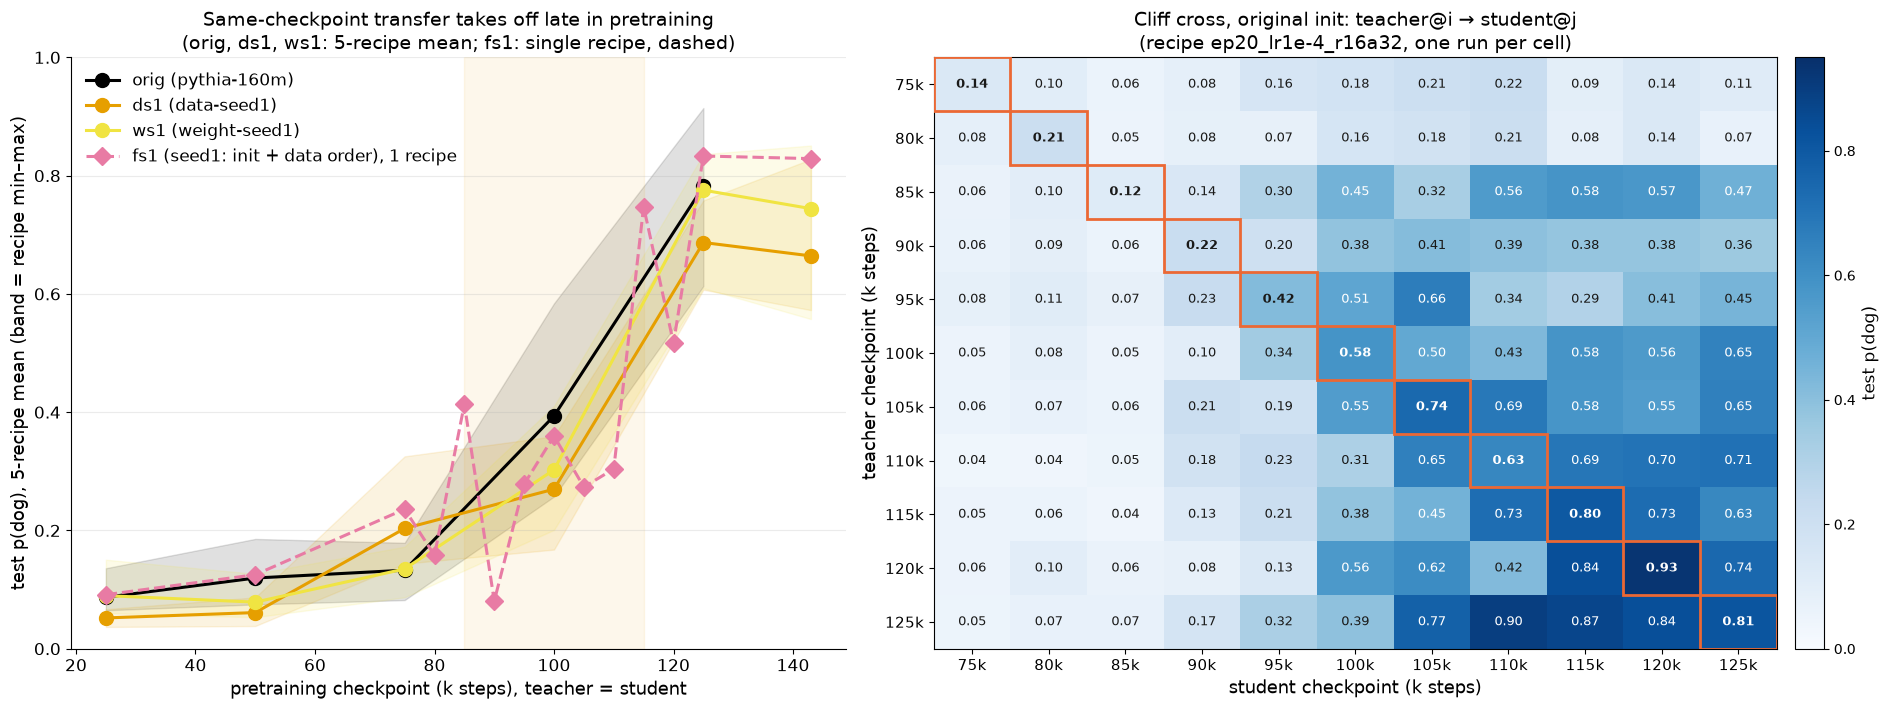

saved /mnt/cold-1/soar-subliminal/angela/outputs/analysis/figures/ckpt_takeoff_and_cliffcross.png


In [23]:
fig, (axl, axr) = plt.subplots(1, 2, figsize=(19, 7.2), gridspec_kw=dict(width_ratios=[1, 1.15]))

# --- left: §1c diagonal takeoff, orig / ds1 / ws1 ---
for init in ["orig", "ds1", "ws1"]:
    s = d3[d3.init == init].groupby("teacher_step").p_test.agg(["mean", "min", "max"])
    axl.plot(s.index / 1000, s["mean"], "-o", color=INIT_COLORS[init], ms=10, lw=2.2,
             label=INIT_LABELS[init])
    axl.fill_between(s.index / 1000, s["min"], s["max"], color=INIT_COLORS[init], alpha=0.12)
if len(d3_fs1):  # fs1 single-recipe diagonal (dashed), see §1c
    s = d3_fs1.groupby("teacher_step").p_test.mean()
    axl.plot(s.index / 1000, s.values, "--D", color=INIT_COLORS["fs1"], ms=9, lw=2.2, label=INIT_LABELS["fs1"])
axl.axvspan(85, 115, color="#eda100", alpha=0.08)
axl.set_xlabel("pretraining checkpoint (k steps), teacher = student", fontsize=13)
axl.set_ylabel("test p(dog), 5-recipe mean (band = recipe min–max)", fontsize=13)
axl.set_title("Same-checkpoint transfer takes off late in pretraining\n(orig, ds1, ws1: 5-recipe mean; fs1: single recipe, dashed)", fontsize=14)
axl.set_ylim(0, 1); axl.tick_params(labelsize=12)
style(axl)
axl.legend(loc="upper left", frameon=False, fontsize=12)

# --- right: §2b orig 11×11 cliff cross ---
xl = [f"{s // 1000}k" for s in XSTEPS]  # local: `lab` is rebound by later sections
im = axr.imshow(X.values, cmap="Blues", vmin=0, vmax=0.95, aspect="auto")
axr.set_xticks(range(len(XSTEPS)), xl, fontsize=11); axr.set_yticks(range(len(XSTEPS)), xl, fontsize=11)
axr.set_xlabel("student checkpoint (k steps)", fontsize=13); axr.set_ylabel("teacher checkpoint (k steps)", fontsize=13)
axr.set_title("Cliff cross, original init: teacher@i → student@j\n(recipe ep20_lr1e-4_r16a32, one run per cell)", fontsize=14)
for a in range(len(XSTEPS)):
    for b in range(len(XSTEPS)):
        v = X.values[a, b]
        if np.isnan(v):
            continue
        axr.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=9.5,
                 color="#ffffff" if v > 0.45 else "#1a1a19", fontweight="bold" if a == b else "normal")
for k in range(len(XSTEPS)):
    axr.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=2, zorder=3))
cb = fig.colorbar(im, ax=axr, fraction=0.035, pad=0.02); cb.set_label("test p(dog)", fontsize=12)
plt.tight_layout()
fig_dir = OUT / "analysis/figures"; fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "ckpt_takeoff_and_cliffcross.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", fig_dir / "ckpt_takeoff_and_cliffcross.png")